# Week 14: Data Engines, Advanced Evaluation & Pipeline Metrics (Demo)

This notebook is the instructor demonstration for Week 14.
Part 1 builds a complete pre-training data pipeline on a mini corpus.
Part 2 implements evaluation metrics from scratch: BLEU/ROUGE, BERTScore, LLM-as-Judge, pass@k, and RAGAS Faithfulness.
No high-level wrappers. Every metric is built step by step to expose the underlying math.

In [1]:
# Required Libraries (minimum versions; the saved outputs were produced with transformers 5.x)
# torch>=2.0.0
# transformers>=4.40.0
# numpy>=1.24.0
# matplotlib>=3.7.0
# seaborn>=0.12.0
# Optional: !pip install -q torch transformers numpy matplotlib seaborn

In [2]:
# ═══════════════════════════════════════════
# SECTION 0: Setup — Device Detection, Seed, Imports
# Theory: We auto-detect MPS (Apple Silicon), CUDA, or CPU so the notebook runs anywhere.
# What this cell does: Import all libraries, set random seed, print device.
# ═══════════════════════════════════════════

import numpy as np
import torch
import hashlib
import re
import math
import random
from collections import defaultdict, Counter

import matplotlib.pyplot as plt
import seaborn as sns

device = 'mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

print(f'Device: {device}')

Device: mps


In [3]:
# ═══════════════════════════════════════════
# SECTION 1: Mini Corpus Setup
# Theory: We use a hardcoded list of 12 documents spanning several quality types:
#   high-quality educational text (incl. a near-duplicate pair, Docs 9-10), mediocre web text,
#   SEO spam, a symbol table, code, Thai text, and Lorem Ipsum.
# What this cell does: Define CORPUS as a list of dicts with 'id', 'text', 'label' keys.
# ═══════════════════════════════════════════

CORPUS = [
    {
        'id': 0,
        'text': ('Gradient descent is an iterative optimisation algorithm used to minimise a differentiable '
                 'objective function L(theta). At each step we compute the gradient nabla L with respect to '
                 'the parameters theta and move in the negative gradient direction: '
                 'theta_{t+1} = theta_t - alpha * nabla L(theta_t). '
                 'The learning rate alpha controls the step size. When alpha is too large the updates '
                 'overshoot the minimum and the loss diverges. When alpha is too small convergence is '
                 'extremely slow. Momentum-based variants such as Adam accumulate a decaying average of '
                 'past gradients to dampen oscillations and accelerate convergence along shallow directions.'),
        'label': 'high_edu'
    },
    {
        'id': 1,
        'text': ('The attention mechanism allows a model to weigh the relevance of every token in the '
                 'input sequence when producing each output token. Given queries Q, keys K, and values V '
                 'the scaled dot-product attention is Attention(Q,K,V) = softmax(QK^T / sqrt(d_k)) V. '
                 'The denominator sqrt(d_k) prevents the dot products from growing so large that the '
                 'softmax saturates into a near-one-hot distribution. Multi-head attention runs h parallel '
                 'attention heads, each with its own learned projection, allowing the model to attend to '
                 'information from different representation subspaces simultaneously.'),
        'label': 'high_edu'
    },
    {
        'id': 2,
        'text': ('Bangkok is a vibrant city full of amazing temples and street food. '
                 'I visited the Grand Palace last week and it was really beautiful. '
                 'The food on Khao San Road is pretty good and affordable. '
                 'If you are planning a trip to Thailand I recommend spending at least three days in Bangkok. '
                 'There are many hotels and hostels to choose from depending on your budget.'),
        'label': 'mediocre'
    },
    {
        'id': 3,
        'text': ('The home team won the championship game last night by a score of 84 to 76. '
                 'The star player scored 28 points in the final quarter to seal the victory. '
                 'The coach praised the team for their hard work and dedication throughout the season. '
                 'Fans celebrated in the streets after the final buzzer sounded. '
                 'The team will now advance to the national finals next month.'),
        'label': 'mediocre'
    },
    {
        'id': 4,
        'text': ('Buy cheap flights NOW! Best prices! Book today! Lowest fares guaranteed! '
                 'Click here to buy cheap flights now! Discount airfare deals! '
                 'Cheap tickets available! Best prices online! Buy now and save! '
                 'Flights from $9! Book cheap flights today! Lowest prices guaranteed! '
                 'Click here now! Buy cheap flights! Save money today! Best deals online!'),
        'label': 'seo_spam'
    },
    {
        'id': 5,
        'text': ('We use cookies to improve your experience. By continuing you agree to our cookie policy. '
                 'We use cookies to improve your experience. By continuing you agree to our cookie policy. '
                 'We use cookies to improve your experience. By continuing you agree to our cookie policy. '
                 'Accept all cookies. Manage preferences. Privacy policy. Terms of service. '
                 'We use cookies to improve your experience. By continuing you agree to our cookie policy.'),
        'label': 'seo_spam'
    },
    {
        'id': 6,
        'text': ('### 2024-01-15 | 99.7% | $1,234.56 | +15.3% | *** ALERT *** | 0x00FF | ID#4892 | NULL | 404 | '
                 'see the table above for the full list of the daily values.'),
        'label': 'low_alpha'
    },
    {
        'id': 7,
        'text': ('การประมวลผลภาษาธรรมชาติเป็นสาขาหนึ่งของปัญญาประดิษฐ์ที่มุ่งเน้นการทำให้คอมพิวเตอร์ '
                 'สามารถเข้าใจและสร้างภาษามนุษย์ได้ '
                 'โมเดลการเรียนรู้เชิงลึกเช่น Transformer ได้เปลี่ยนแปลงวงการนี้อย่างมาก'),
        'label': 'thai'
    },
    {
        'id': 8,
        'text': 'function init() { var x = 0; if (x > 0) { return true; } else { return false; } } // javascript',
        'label': 'code_template'
    },
    {
        'id': 9,
        'text': ('In the Transformer architecture, self-attention allows each token to directly attend '
                 'to every other token in the sequence regardless of distance. '
                 'The attention score between token i and token j is computed as the dot product of their '
                 'query and key vectors, scaled by the square root of the key dimension d_k. '
                 'This scaling prevents the softmax from saturating when d_k is large. '
                 'The output for each token is a weighted sum of the value vectors, where the weights '
                 'are the softmax-normalised attention scores. '
                 'Positional encodings are added to the input embeddings to inject information about '
                 'the order of tokens: self-attention is permutation-equivariant, so permuting the '
                 'inputs permutes the outputs rather than leaving them unchanged. '
                 'The encoder uses bidirectional attention while the decoder uses masked attention to '
                 'prevent attending to future tokens during autoregressive generation.'),
        'label': 'high_edu'
    },
    {
        'id': 10,
        'text': ('In the Transformer model, self-attention enables each token to directly attend '
                 'to every other token in the sequence regardless of distance. '
                 'The attention score between position i and position j is calculated as the dot product '
                 'of their query and key vectors, scaled by the square root of the key dimension d_k. '
                 'This scaling stops the softmax from saturating when d_k is large. '
                 'The output for each token is a weighted sum of the value vectors, where the weights '
                 'are the softmax-normalised attention scores. '
                 'Positional encodings are added to the input embeddings to provide information about '
                 'the order of tokens: self-attention is permutation-equivariant, so permuting the inputs '
                 'permutes the outputs rather than leaving them unchanged. '
                 'The encoder applies bidirectional attention while the decoder uses masked attention to '
                 'avoid attending to future tokens during autoregressive decoding.'),
        'label': 'high_edu'
    },
    {
        'id': 11,
        'text': ('Lorem ipsum dolor sit amet, consectetur adipiscing elit, sed do eiusmod tempor '
                 'incididunt ut labore et dolore magna aliqua. '
                 'Ut enim ad minim veniam, quis nostrud exercitation ullamco laboris nisi ut aliquip '
                 'ex ea commodo consequat. '
                 'Duis aute irure dolor in reprehenderit in voluptate velit esse cillum dolore eu fugiat '
                 'nulla pariatur.'),
        'label': 'lorem_ipsum'
    }
]

print(f'Corpus loaded: {len(CORPUS)} documents')
for doc in CORPUS:
    preview = doc['text'][:70].replace('\n', ' ')
    print(f'  Doc {doc["id"]:2d} [{doc["label"]:15s}]: {preview}...')

Corpus loaded: 12 documents
  Doc  0 [high_edu       ]: Gradient descent is an iterative optimisation algorithm used to minimi...
  Doc  1 [high_edu       ]: The attention mechanism allows a model to weigh the relevance of every...
  Doc  2 [mediocre       ]: Bangkok is a vibrant city full of amazing temples and street food. I v...
  Doc  3 [mediocre       ]: The home team won the championship game last night by a score of 84 to...
  Doc  4 [seo_spam       ]: Buy cheap flights NOW! Best prices! Book today! Lowest fares guarantee...
  Doc  5 [seo_spam       ]: We use cookies to improve your experience. By continuing you agree to ...
  Doc  6 [low_alpha      ]: ### 2024-01-15 | 99.7% | $1,234.56 | +15.3% | *** ALERT *** | 0x00FF |...
  Doc  7 [thai           ]: การประมวลผลภาษาธรรมชาติเป็นสาขาหนึ่งของปัญญาประดิษฐ์ที่มุ่งเน้นการทำให...
  Doc  8 [code_template  ]: function init() { var x = 0; if (x > 0) { return true; } else { return...
  Doc  9 [high_edu       ]: In the Transformer archite

## Part 1: The Pre-Training Data Factory

Walk through the cleaning pipeline in cheap-to-expensive order (slides 10-31):
Language ID -> Gopher rules -> C4 rules -> Perplexity (CCNet-style) -> Deduplication (SHA-256, MinHash, LSH).
Each stage reduces the corpus. Track retention at each step.


In [4]:
# ═══════════════════════════════════════════
# SECTION 2: Language Identification (Character N-gram Classifier)  — slide 7
# Theory: fastText lid.176 uses character n-gram bag-of-words embeddings. We simulate this
#   with two cheap signals: the fraction of non-ASCII characters (Thai script) and the
#   number of common English function words present.
# What this cell does: Implement detect_language() and route documents with a 0.65 threshold
#   (the value FineWeb used for its fastText English filter).
# ═══════════════════════════════════════════

ENGLISH_FUNCTION_WORDS = {'the', 'is', 'are', 'of', 'in', 'to', 'and', 'a', 'an', 'it', 'that',
                          'for', 'you', 'your', 'our', 'this', 'by', 'with', 'on', 'now', 'here'}

def detect_language(text):
    '''Detect language using byte-level and function-word heuristics.
    Returns (lang_code, confidence).
    '''
    if not text:
        return ('unknown', 0.0)

    # Fraction of characters outside ASCII (Thai script is entirely non-ASCII)
    non_ascii_frac = sum(1 for c in text if ord(c) > 127) / max(1, len(text))
    if non_ascii_frac > 0.25:
        return ('th', 0.80)

    words = set(re.findall(r"[a-z']+", text.lower()))
    hits = len(words & ENGLISH_FUNCTION_WORDS)
    if hits >= 3:
        return ('en', 0.92)   # clearly English prose
    if hits >= 1:
        return ('en', 0.70)   # weak evidence: spam, lists, Latin filler
    return ('unknown', 0.45)  # code, symbol tables


LANG_THRESHOLD = 0.65   # FineWeb: keep English with fastText score >= 0.65

print(f'{"Doc":>4}  {"Lang":>7}  {"Conf":>5}  {"Decision":>8}  Preview')
print('-' * 80)

lang_results = []
for doc in CORPUS:
    lang, conf = detect_language(doc['text'])
    keep = (lang == 'en' and conf >= LANG_THRESHOLD)   # English-only corpus for this demo
    decision = 'KEEP' if keep else 'DROP'
    preview = doc['text'][:56].replace('\n', ' ')
    print(f'{doc["id"]:>4}  {lang:>7}  {conf:>5.2f}  {decision:>8}  {preview}')
    lang_results.append({'doc': doc, 'lang': lang, 'conf': conf, 'keep': keep})

lang_filtered = [r['doc'] for r in lang_results if r['keep']]
print()
print(f'After Language Filter: {len(lang_filtered)}/{len(CORPUS)} documents kept')
print('Note: the Thai document is dropped only because this demo builds an ENGLISH corpus.')
print('      A multilingual pipeline would route it to a Thai-specific branch instead.')


 Doc     Lang   Conf  Decision  Preview
--------------------------------------------------------------------------------
   0       en   0.92      KEEP  Gradient descent is an iterative optimisation algorithm 
   1       en   0.92      KEEP  The attention mechanism allows a model to weigh the rele
   2       en   0.92      KEEP  Bangkok is a vibrant city full of amazing temples and st
   3       en   0.92      KEEP  The home team won the championship game last night by a 
   4       en   0.92      KEEP  Buy cheap flights NOW! Best prices! Book today! Lowest f
   5       en   0.92      KEEP  We use cookies to improve your experience. By continuing
   6       en   0.92      KEEP  ### 2024-01-15 | 99.7% | $1,234.56 | +15.3% | *** ALERT 
   7       th   0.80      DROP  การประมวลผลภาษาธรรมชาติเป็นสาขาหนึ่งของปัญญาประดิษฐ์ที่ม
   8  unknown   0.45      DROP  function init() { var x = 0; if (x > 0) { return true; }
   9       en   0.92      KEEP  In the Transformer architecture, self-attentio

In [5]:
# ═══════════════════════════════════════════
# SECTION 3: Tokenizer Efficiency — Token/Character Rate (TPC)  — slides 8-9
# Theory: TPC = tokens / Unicode characters. (We avoid the word "fertility", which in the
#   literature means subword pieces per WORD — Thai has no reliable whitespace word boundary.)
#   A BPE vocabulary learned mostly on English lacks merges for Thai byte sequences, so Thai
#   costs several tokens per character. Rate ratio rho = TPC_TH / TPC_EN.
# What this cell does: Load GPT-2 and BERT tokenizers, compute TPC on one EN/TH sentence pair,
#   and check for [UNK] loss (a tokenizer that maps Thai to [UNK] has a meaningless TPC).
# ═══════════════════════════════════════════

from transformers import AutoTokenizer

gpt2_tok = AutoTokenizer.from_pretrained('gpt2')
bert_tok = AutoTokenizer.from_pretrained('bert-base-uncased')

en_text = 'Natural language processing enables computers to understand human text.'
th_text = 'การประมวลผลภาษาธรรมชาติช่วยให้คอมพิวเตอร์เข้าใจภาษามนุษย์'

def tokens_per_character(text, tokenizer):
    '''TPC = number of tokens / number of Unicode characters. Also returns the [UNK] count.'''
    ids = tokenizer.encode(text, add_special_tokens=False)
    unk = sum(1 for i in ids if i == tokenizer.unk_token_id) if tokenizer.unk_token_id is not None else 0
    return len(ids) / max(1, len(text)), len(ids), unk


print(f'EN text ({len(en_text)} chars): {en_text}')
print(f'TH text ({len(th_text)} chars): {th_text}')
print()
print(f'{"Tokenizer":<20}  {"EN tokens":>9}  {"TPC EN":>7}  {"TH tokens":>9}  {"TPC TH":>7}  {"TH [UNK]":>8}  {"rho":>6}')
print('-' * 80)

for tok_name, tokenizer in [('GPT-2 (50k BPE)', gpt2_tok), ('BERT-base-uncased', bert_tok)]:
    tpc_en, n_en, _      = tokens_per_character(en_text, tokenizer)
    tpc_th, n_th, unk_th = tokens_per_character(th_text, tokenizer)
    rho = tpc_th / max(tpc_en, 1e-9)
    flag = '  <- [UNK] loss: TPC meaningless' if unk_th else ''
    print(f'{tok_name:<20}  {n_en:>9}  {tpc_en:>7.3f}  {n_th:>9}  {tpc_th:>7.3f}  {unk_th:>8}  {rho:>5.1f}x{flag}')

print()
print('GPT-2 tokens for the Thai sentence (first 12):', gpt2_tok.convert_ids_to_tokens(gpt2_tok.encode(th_text))[:12])
print()
print('Reading: GPT-2 spends ~2 tokens per Thai character (3 UTF-8 bytes each, few learned merges),')
print('  ~14x the English rate on THIS pair. Measure on parallel corpora before quoting a cost multiplier.')
print('  BERT-base-uncased shows the opposite trap: Thai collapses to a single [UNK], so its low TPC is a')
print('  coverage failure, not efficiency. Always check [UNK] counts before comparing TPC.')


EN text (71 chars): Natural language processing enables computers to understand human text.
TH text (57 chars): การประมวลผลภาษาธรรมชาติช่วยให้คอมพิวเตอร์เข้าใจภาษามนุษย์

Tokenizer             EN tokens   TPC EN  TH tokens   TPC TH  TH [UNK]     rho
--------------------------------------------------------------------------------
GPT-2 (50k BPE)              10    0.141        114    2.000         0   14.2x
BERT-base-uncased            10    0.141          1    0.018         1    0.1x  <- [UNK] loss: TPC meaningless

GPT-2 tokens for the Thai sentence (first 12): ['à¸', 'ģ', 'à¸', '²', 'à¸', '£', 'à¸', 'Ľ', 'à¸', '£', 'à¸', '°']

Reading: GPT-2 spends ~2 tokens per Thai character (3 UTF-8 bytes each, few learned merges),
  ~14x the English rate on THIS pair. Measure on parallel corpora before quoting a cost multiplier.
  BERT-base-uncased shows the opposite trap: Thai collapses to a single [UNK], so its low TPC is a
  coverage failure, not efficiency. Always check [UNK] counts before co

In [6]:
# ═══════════════════════════════════════════
# SECTION 4: Selected Gopher QUALITY Rules — Heuristic Filters (Part 1)  — slide 11
# Theory: A SUBSET of the Gopher rules (Rae et al. 2021, Appendix A). We implement the quality
#   filters only. Gopher also applies REPETITION filters (duplicate line/paragraph fractions,
#   most-frequent n-gram fractions) which we do NOT implement — remember that when reading the
#   results below. The quality filters implemented here are 5 of the 7 rule groups on slide 11:
#   50 <= words <= 100k; 3 <= mean word length <= 10; >= 80% of words contain a letter;
#   (# or ...) symbol-to-word ratio <= 0.1; >= 2 English stop words. All rules must pass.
#   ALSO NOT IMPLEMENTED: the LINE rules on slide 11 (<= 90% of lines start with a bullet,
#   <= 30% of lines end with '...'). Every document in this mini-corpus is a single line, so
#   those two rules would pass trivially for all 12 and teach nothing. On real Common Crawl
#   text, where a page is many lines, they are what remove navigation menus and feed listings.
#   "Words" are whitespace tokens — Thai text must be word-segmented first (e.g. PyThaiNLP)
#   or it fails word_count/mean_word_len for the wrong reason.
# What this cell does: Implement gopher_filter(text) -> (bool, dict_of_rule_results).
# ═══════════════════════════════════════════

GOPHER_STOP_WORDS = {'the', 'be', 'to', 'of', 'and', 'that', 'have', 'with'}

def gopher_filter(text):
    '''Apply Gopher quality rules to a document.
    Returns (passed: bool, results: dict mapping rule_name to (pass, description)).
    '''
    words = text.split()
    n_words = len(words)
    alpha_words = [w for w in words if any(c.isalpha() for c in w)]
    symbol_count = text.count('#') + text.count('...')
    mean_word_len = sum(len(w) for w in words) / max(1, n_words)
    stop_hits = len({w.lower().strip('.,!?') for w in words} & GOPHER_STOP_WORDS)

    results = {
        'word_count':    (50 <= n_words <= 100000,            f'{n_words} words'),
        'mean_word_len': (3.0 <= mean_word_len <= 10.0,       f'{mean_word_len:.2f} chars/word'),
        'alpha_ratio':   (len(alpha_words) / max(1, n_words) >= 0.80,
                          f'{len(alpha_words)/max(1,n_words):.2f}'),
        'symbol_ratio':  (symbol_count / max(1, n_words) <= 0.10,
                          f'{symbol_count/max(1,n_words):.3f}'),
        'stop_words':    (stop_hits >= 2,                     f'{stop_hits} stop words'),
    }
    passed = all(v[0] for v in results.values())
    return passed, results


print(f'{"Doc":>4}  {"Label":>13}  {"words":>10}  {"mean_wlen":>14}  {"alpha":>10}  {"symbol":>11}  {"stopw":>9}  {"PASS":>5}')
print('-' * 100)

gopher_pass = []
for doc in CORPUS:
    passed, r = gopher_filter(doc['text'])
    def cell(name): return ('OK ' if r[name][0] else 'F ') + r[name][1]
    print(f'{doc["id"]:>4}  {doc["label"]:>13}  {cell("word_count"):>10}  {cell("mean_word_len"):>14}  '
          f'{cell("alpha_ratio"):>10}  {cell("symbol_ratio"):>11}  {cell("stop_words"):>9}  {("PASS" if passed else "FAIL"):>5}')
    if passed:
        gopher_pass.append(doc)

print()
print(f'After Gopher Filter (applied to ALL docs for illustration): {len(gopher_pass)}/{len(CORPUS)} documents')
print('Read the failures: the numeric table and the code fail alpha_ratio. The Thai document fails')
print('word_count and mean_word_len because it was never word-segmented (5 "words" of ~37 chars) AND')
print('stop_words, because the stop-word list is English. Segmentation alone would not rescue it:')
print('a Thai branch needs language-specific word, length and stop-word rules.')
print()
print('NOT implemented here, two groups. (1) The LINE rules from slide 11 (bullet-start and')
print("'...'-ending line fractions): our docs are single-line, so they would pass trivially.")
print('(2) Gopher\'s REPETITION filters (duplicate lines/paragraphs, most-frequent n-gram share).')
print('The repeated cookie banner (Doc 5) would be a target for those. This table is a SUBSET.')


 Doc          Label       words       mean_wlen       alpha       symbol      stopw   PASS
----------------------------------------------------------------------------------------------------
   0       high_edu  OK 97 words  OK 5.61 chars/word     OK 0.97     OK 0.000  OK 5 stop words   PASS
   1       high_edu  OK 85 words  OK 5.85 chars/word     OK 0.98     OK 0.000  OK 6 stop words   PASS
   2       mediocre  OK 65 words  OK 4.49 chars/word     OK 1.00     OK 0.000  OK 4 stop words   PASS
   3       mediocre  OK 65 words  OK 4.52 chars/word     OK 0.95     OK 0.000  OK 4 stop words   PASS
   4       seo_spam  OK 53 words  OK 5.38 chars/word     OK 0.98     OK 0.000  OK 2 stop words   PASS
   5       seo_spam  OK 70 words  OK 5.14 chars/word     OK 1.00     OK 0.000  OK 2 stop words   PASS
   6      low_alpha  F 33 words  OK 3.64 chars/word      F 0.48      F 0.121  OK 2 stop words   FAIL
   7           thai   F 5 words  F 36.60 chars/word     OK 1.00     OK 0.000  F 0 stop words   

In [7]:
# ═══════════════════════════════════════════
# SECTION 5: C4 Rules — Heuristic Filters (Part 2)  — slide 12
# Theory: C4 rules (Raffel et al. 2020, Sec. 2.2).
#   Page-level: drop the page if it contains 'lorem ipsum' or a curly bracket '{'.
#   Line-level (C4): keep only lines that end in terminal punctuation, have >= 3 words, and do not
#   contain the word 'javascript'. Page-level (C4): drop the page if fewer than 5 sentences survive.
#   Our mini-corpus docs are single paragraphs, so we treat SENTENCES as C4's "lines".
#   NOTE 1: C4 CLEANS a page by deleting bad lines and keeps the cleaned text. To keep the funnel
#     simple we only make a keep/drop decision and return the ORIGINAL text; a production pipeline
#     must propagate the cleaned document.
#   NOTE 2: the thresholds BELOW are tuned for this 12-document toy corpus, not C4's: we require
#     >= 5 words per line and >= 3 surviving sentences per page. C4's own values (>= 3 words,
#     >= 5 sentences) were chosen for Common Crawl and would drop our short single-paragraph docs.
#   NOTE 3: the "kept fraction" we report is diagnostic only -- Raffel et al. prescribe no bad-line
#     percentage threshold at all; that number is ours.
# What this cell does: Implement c4_filter(text) -> (passed, kept_fraction, reason).
# ═══════════════════════════════════════════

def c4_filter(text):
    '''Apply C4 quality rules. Returns (passed: bool, kept_fraction: float, reason: str).'''
    low = text.lower()
    if 'lorem ipsum' in low:
        return False, 0.0, "page contains 'lorem ipsum'"
    if '{' in text:
        return False, 0.0, "page contains '{' (code/markup)"

    # Split into "lines" (sentences for our one-paragraph docs)
    lines = [s.strip() for s in re.split(r'(?<=[.!?"])\s+', text) if s.strip()]
    if not lines:
        return False, 0.0, 'empty'

    def good_line(line):
        return (line[-1] in '.?!"'                 # terminal punctuation
                and len(line.split()) >= 5         # >= 5 words (corpus-tuned; C4 uses 3)
                and 'javascript' not in line.lower())

    kept = [l for l in lines if good_line(l)]
    kept_frac = len(kept) / len(lines)
    if len(kept) < 3:                              # corpus-tuned; C4 drops pages under 5 sentences
        return False, kept_frac, f'only {len(kept)} sentence(s) survive (< 3)'
    # Production note: the cleaned document is ' '.join(kept) — that is what should flow onward.
    return True, kept_frac, 'passed'


print(f'{"Doc":>4}  {"Label":>13}  {"kept":>5}  {"Decision":>8}  Reason')
print('-' * 75)

c4_pass = []
for doc in CORPUS:
    passed, kept_frac, reason = c4_filter(doc['text'])
    print(f'{doc["id"]:>4}  {doc["label"]:>13}  {kept_frac:>5.2f}  {("KEEP" if passed else "DROP"):>8}  {reason}')
    if passed:
        c4_pass.append(doc)

print()
print(f'After C4 Filter (applied to ALL docs for illustration): {len(c4_pass)}/{len(CORPUS)} documents')
print("Collateral damage: Doc 0 (a good gradient-descent explanation) is dropped because its LaTeX-style")
print("'theta_{t+1}' contains '{'. Heuristics are cheap but blunt — audit what they remove.")


 Doc          Label   kept  Decision  Reason
---------------------------------------------------------------------------
   0       high_edu   0.00      DROP  page contains '{' (code/markup)
   1       high_edu   1.00      KEEP  passed
   2       mediocre   1.00      KEEP  passed
   3       mediocre   1.00      KEEP  passed
   4       seo_spam   0.06      DROP  only 1 sentence(s) survive (< 3)
   5       seo_spam   0.67      KEEP  passed
   6      low_alpha   1.00      DROP  only 1 sentence(s) survive (< 3)
   7           thai   0.00      DROP  only 0 sentence(s) survive (< 3)
   8  code_template   0.00      DROP  page contains '{' (code/markup)
   9       high_edu   1.00      KEEP  passed
  10       high_edu   1.00      KEEP  passed
  11    lorem_ipsum   0.00      DROP  page contains 'lorem ipsum'

After C4 Filter (applied to ALL docs for illustration): 6/12 documents
Collateral damage: Doc 0 (a good gradient-descent explanation) is dropped because its LaTeX-style
'theta_{t+1}' contai

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Reference LM: distilgpt2. Documents sorted by perplexity (CCNet head / middle / tail):
Thresholds placed at PPL 57.2 and 66.4 — the points where cumulative
character mass crosses 1/3 and 2/3 of the 5,055 characters.

 Doc      PPL   chars    cum%   Bucket          Label  Preview
-----------------------------------------------------------------------------------------------
   5      4.1     429    8.5%     head       seo_spam  We use cookies to improve your exp...
   8      9.2      95   10.4%     head  code_template  function init() { var x = 0; if (x...
   3     20.0     358   17.4%     head       mediocre  The home team won the championship...
   2     20.9     356   24.5%     head       mediocre  Bangkok is a vibrant city full of ...
   4     49.4     337   31.2%     head       seo_spam  Buy cheap flights NOW! Best prices...
   6     65.0     152   34.2%   middle      low_alpha  ### 2024-01-15 | 99.7% | $1,234.56...
  10     66.1     886   51.7%   middle       high_edu  In the Tran

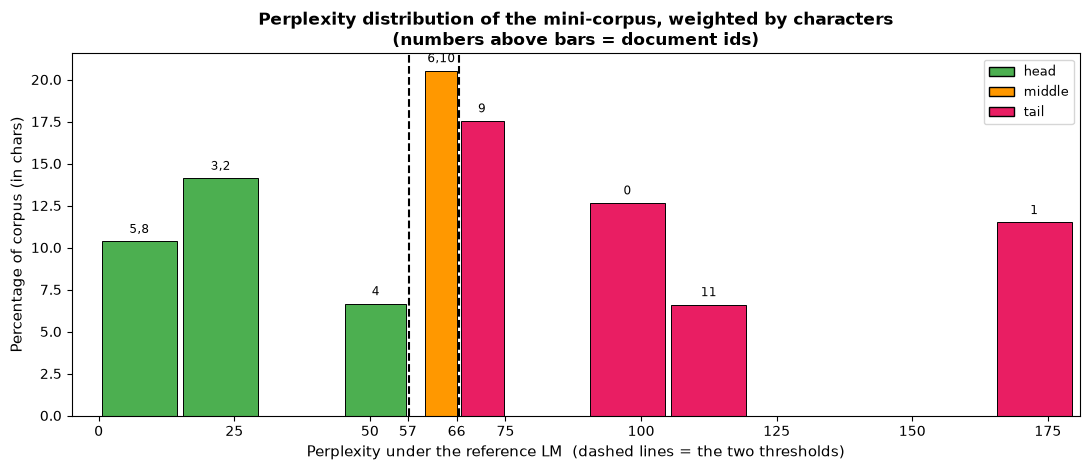

Read it exactly as CCNet reads Figure 7. Bar height is the share of the corpus by CHARACTERS,
not by document count. The two dashed lines are the thresholds: they were placed where the
character mass running left-to-right passes a third and two thirds, and a document is then
routed whole by which side of the lines its own perplexity falls on.
Note Doc 9 and Doc 10 — near-identical documents 0.5 apart in perplexity, sitting either side
of the second threshold and landing in different buckets. Terciles are an operating
convention, not a quality boundary. With 11 documents the bars are chunky; CCNet runs this
over billions, which is why its Figure 7 looks like a smooth curve instead.

Keeping buckets ['head', 'middle']: 7/11 English documents

THE CCNET TRAP (slide 15): the repeated cookie banner (Doc 5) has the LOWEST perplexity of all
  11 scored documents — repetition is highly predictable. Meanwhile the high-quality maths and attention
  explanations (Docs 0, 1) land in the TAIL becau

In [8]:
# ═══════════════════════════════════════════
# SECTION 6: Perplexity Filter (CCNet-style)  — slides 14-15
# Theory: PPL = exp(-1/N * sum log P(w_i | context)) under a reference LM. CCNet trains a KenLM
#   5-gram on Wikipedia; we use pretrained DistilGPT-2 (web text) as the reference LM.
#   CCNet does NOT use a fixed cut-off: per language it picks two PPL thresholds and routes whole
#   documents into head / middle / tail, then lets the user pick buckets.
#   Thresholds are placed so the three buckets hold equal DATA SIZE in characters (CCNet's Figure 7
#   y-axis is "percentage of corpus (in chars)"), NOT equal document counts. We follow that here,
#   so our bucket document-counts come out uneven — which is the point.
# The plot below mirrors CCNet's Figure 7: where the two vertical threshold lines fall, and how the
#   character mass accumulates to the 1/3 and 2/3 marks that put them there.
# What this cell does: Compute PPL per document, assign head/middle/tail, and expose the trap:
#   repetitive spam gets the LOWEST perplexity.
# ═══════════════════════════════════════════

from transformers import AutoModelForCausalLM

model_name = 'distilgpt2'
ppl_tokenizer = AutoTokenizer.from_pretrained(model_name)
ppl_model = AutoModelForCausalLM.from_pretrained(model_name).to(device)
ppl_model.eval()

def compute_perplexity(text, model, tokenizer, max_len=512):
    '''Perplexity of text under a causal LM = exp(mean token cross-entropy).'''
    if not text.strip():
        return float('inf')
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=max_len)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputs, labels=inputs['input_ids'])
    return math.exp(outputs.loss.item())


def ppl_buckets(ppl_by_id, chars_by_id):
    '''CCNet-style bucketing, in the paper's two steps.

    STEP 1 (once per language): choose two perplexity thresholds so that the three buckets hold
      equal DATA SIZE — a third of the corpus characters each. Long documents therefore weigh more
      than short ones when the thresholds are placed.
    STEP 2 (per document): route each WHOLE document by its own perplexity against those thresholds.
      Nothing is ever split; a document is kept or dropped intact.

    Returns (bucket_by_id, (threshold_1, threshold_2)).
    '''
    order = sorted(ppl_by_id, key=lambda i: ppl_by_id[i])
    total = sum(chars_by_id[i] for i in order)
    bucket, cum = {}, 0
    for doc_id in order:                                   # STEP 1: walk up the PPL axis,
        cum += chars_by_id[doc_id]                         #   accumulating character mass
        frac = cum / total
        bucket[doc_id] = 'head' if frac <= 1/3 else ('middle' if frac <= 2/3 else 'tail')
    cuts = []
    for lo, hi in (('head', 'middle'), ('middle', 'tail')):  # a threshold sits between the last
        last = [i for i in order if bucket[i] == lo][-1]     #   document of one bucket and the
        first = [i for i in order if bucket[i] == hi][0]     #   first of the next
        cuts.append((ppl_by_id[last] + ppl_by_id[first]) / 2)
    return bucket, tuple(cuts)


# English-script documents only: a GPT-2 PPL on Thai is not meaningful (byte fallback, no training data)
english_docs = [doc for doc in CORPUS if doc['label'] != 'thai']
ppl_by_id = {doc['id']: compute_perplexity(doc['text'], ppl_model, ppl_tokenizer) for doc in english_docs}
chars_by_id = {doc['id']: len(doc['text']) for doc in english_docs}
bucket_by_id, (ppl_cut_1, ppl_cut_2) = ppl_buckets(ppl_by_id, chars_by_id)
total_chars = sum(chars_by_id.values())

print(f'Reference LM: {model_name}. Documents sorted by perplexity (CCNet head / middle / tail):')
print(f'Thresholds placed at PPL {ppl_cut_1:.1f} and {ppl_cut_2:.1f} — the points where cumulative')
print(f'character mass crosses 1/3 and 2/3 of the {total_chars:,} characters.')
print()
print(f'{"Doc":>4}  {"PPL":>7}  {"chars":>6}  {"cum%":>6}  {"Bucket":>7}  {"Label":>13}  Preview')
print('-' * 95)
running = 0
for doc_id in sorted(ppl_by_id, key=lambda i: ppl_by_id[i]):
    doc = CORPUS[doc_id]
    running += chars_by_id[doc_id]
    print(f'{doc_id:>4}  {ppl_by_id[doc_id]:>7.1f}  {chars_by_id[doc_id]:>6}  {100*running/total_chars:>5.1f}%  '
          f'{bucket_by_id[doc_id]:>7}  {doc["label"]:>13}  {doc["text"][:34]}...')

bucket_docs = {b: sum(1 for v in bucket_by_id.values() if v == b) for b in ('head', 'middle', 'tail')}
bucket_chars = {b: sum(chars_by_id[i] for i, v in bucket_by_id.items() if v == b) for b in ('head', 'middle', 'tail')}
print()
print(f'{"Bucket":>7}  {"Docs":>5}  {"Chars":>7}  {"Share":>6}')
for b in ('head', 'middle', 'tail'):
    print(f'{b:>7}  {bucket_docs[b]:>5}  {bucket_chars[b]:>7}  {100*bucket_chars[b]/total_chars:>5.1f}%')
print('Two things to read off this table. (1) The document counts are uneven (5 / 2 / 4) even though')
print('  the rule targets equal character mass — that is the difference from splitting by count.')
print('  (2) The character shares are uneven TOO (31 / 20 / 48%), because a document cannot be cut in')
print('  half: the boundary lands wherever the next whole document happens to fall. With 11 documents')
print('  that granularity is brutal; across billions of Common Crawl documents it vanishes and the')
print('  thirds come out near-exact. Our corpus shows the mechanism, not the precision.')

# --- CCNet Figure 7, rebuilt on our mini-corpus -------------------------------------------------
# Same axes as the paper: perplexity across the bottom, percentage of the corpus IN CHARACTERS up
# the side, and the two chosen thresholds as vertical lines. CCNet plots one curve per language
# (English and Gujarati); we have one reference LM, so we plot one histogram and colour each bar
# by its bucket. The thresholds are forced to be BIN EDGES, so no bar ever straddles a line and
# every bar has exactly one colour.
bucket_colour = {'head': '#4CAF50', 'middle': '#FF9800', 'tail': '#E91E63'}
order = sorted(ppl_by_id, key=lambda i: ppl_by_id[i])

BIN_WIDTH = 15
max_ppl = max(ppl_by_id.values())
edges = set(np.arange(0, max_ppl + BIN_WIDTH, BIN_WIDTH).tolist())
edges |= {ppl_cut_1, ppl_cut_2}                     # thresholds become bin boundaries
edges = sorted(e for e in edges if e <= max_ppl + BIN_WIDTH)
edges = [e for j, e in enumerate(edges) if j == 0 or e - edges[j - 1] > 1.0]

fig, ax = plt.subplots(figsize=(11, 4.8))
for lo, hi in zip(edges[:-1], edges[1:]):
    in_bin = [i for i in order if lo <= ppl_by_id[i] < hi]
    if not in_bin:
        continue
    assert len({bucket_by_id[i] for i in in_bin}) == 1, 'a bin straddled a threshold'
    pct = 100.0 * sum(chars_by_id[i] for i in in_bin) / total_chars
    ax.bar((lo + hi) / 2, pct, width=(hi - lo) * 0.92, color=bucket_colour[bucket_by_id[in_bin[0]]],
           edgecolor='black', linewidth=0.7)
    ax.text((lo + hi) / 2, pct + 0.5, ','.join(str(i) for i in in_bin), ha='center', fontsize=8.5)

for cut, name in ((ppl_cut_1, 'head | middle'), (ppl_cut_2, 'middle | tail')):
    ax.axvline(cut, color='black', linestyle='--', linewidth=1.5)
ax.set_xticks(list(ax.get_xticks()) + [round(ppl_cut_1), round(ppl_cut_2)])
ax.set_xlim(-5, max_ppl + BIN_WIDTH)

ax.set_xlabel('Perplexity under the reference LM  (dashed lines = the two thresholds)', fontsize=11)
ax.set_ylabel('Percentage of corpus (in chars)', fontsize=11)
ax.set_title('Perplexity distribution of the mini-corpus, weighted by characters\n'
             '(numbers above bars = document ids)', fontsize=12, fontweight='bold')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, ec='black') for c in bucket_colour.values()],
          labels=list(bucket_colour.keys()), fontsize=9)
plt.tight_layout()
plt.show()

print('Read it exactly as CCNet reads Figure 7. Bar height is the share of the corpus by CHARACTERS,')
print('not by document count. The two dashed lines are the thresholds: they were placed where the')
print('character mass running left-to-right passes a third and two thirds, and a document is then')
print('routed whole by which side of the lines its own perplexity falls on.')
print('Note Doc 9 and Doc 10 — near-identical documents 0.5 apart in perplexity, sitting either side')
print('of the second threshold and landing in different buckets. Terciles are an operating')
print('convention, not a quality boundary. With 11 documents the bars are chunky; CCNet runs this')
print('over billions, which is why its Figure 7 looks like a smooth curve instead.')


KEEP_BUCKETS = {'head', 'middle'}   # CCNet users often keep head+middle
ppl_keep_ids = {i for i, b in bucket_by_id.items() if b in KEEP_BUCKETS}
print()
print(f'Keeping buckets {sorted(KEEP_BUCKETS)}: {len(ppl_keep_ids)}/{len(ppl_by_id)} English documents')
print()
print('THE CCNET TRAP (slide 15): the repeated cookie banner (Doc 5) has the LOWEST perplexity of all')
print('  11 scored documents — repetition is highly predictable. Meanwhile the high-quality maths and attention')
print('  explanations (Docs 0, 1) land in the TAIL because of their rare technical vocabulary.')
print('  (The flight-ad spam, Doc 4, lands mid-table: low perplexity is a risk, not a guarantee.)')
print('  Perplexity measures similarity to the REFERENCE MODEL distribution, not quality.')
print()
print('Caveat: this is a DistilGPT-2 illustration of how the trap arises, not a replication of CCNet.')
print('  CCNet scores with a KenLM 5-gram trained on Wikipedia; a different reference model and')
print('  training domain would bucket these documents differently.')


In [9]:
# ═══════════════════════════════════════════
# SECTION 7: Exact Deduplication — SHA-256 Hashing  — slide 21
# Theory: SHA-256 is a cryptographic hash function that produces a 256-bit (64 hex char)
#   fingerprint. Identical documents produce identical hashes. Hash set lookup is O(1).
#   Collision probability for a GIVEN PAIR ~2^-256; across n documents the any-pair probability is
#   ~n(n-1)/2^257 — still utterly negligible.
#   Storage note: hexdigest() returns a 64-CHARACTER string. A packed digest() is 32 bytes; a Python
#   set of either carries substantial per-object overhead on top.
# What this cell does: Implement exact_dedup(docs) using hashlib.sha256.
# ═══════════════════════════════════════════

def exact_dedup(docs):
    '''Remove exact duplicates using SHA-256 hashing.
    Returns (unique_docs, duplicate_ids).
    '''
    seen_hashes = set()
    unique_docs = []
    duplicate_ids = []

    for doc in docs:
        h = hashlib.sha256(doc['text'].lower().strip().encode('utf-8')).hexdigest()
        if h not in seen_hashes:
            seen_hashes.add(h)
            unique_docs.append(doc)
        else:
            duplicate_ids.append(doc['id'])
    return unique_docs, duplicate_ids


print('SHA-256 fingerprints for all corpus documents:')
print(f'{"Doc":>4}  {"Label":>15}  {"Hash (first 16 hex chars)"}  {"Hash (last 8)"}')
print('-' * 70)

seen_hashes = set()
for doc in CORPUS:
    h = hashlib.sha256(doc['text'].lower().strip().encode('utf-8')).hexdigest()
    is_dup = '** DUPLICATE **' if h in seen_hashes else ''
    print(f'{doc["id"]:>4}  {doc["label"]:>15}  {h[:16]}...{h[-8:]}  {is_dup}')
    seen_hashes.add(h)

unique_docs, dup_ids = exact_dedup(CORPUS)
print()
print(f'Exact duplicates found: {len(dup_ids)} (ids: {dup_ids})')
print(f'After exact dedup: {len(unique_docs)}/{len(CORPUS)} documents retained')
print()
print('Note: Doc 9 and Doc 10 are near-duplicates (word-level changes) but NOT exact duplicates.')
print('SHA-256 cannot catch near-duplicates. That requires MinHash (next section).')

SHA-256 fingerprints for all corpus documents:
 Doc            Label  Hash (first 16 hex chars)  Hash (last 8)
----------------------------------------------------------------------
   0         high_edu  7e9c83c90af8788e...b2d56b82  
   1         high_edu  3849f6c7d81a7663...45ca1930  
   2         mediocre  ada5ac165455ea69...a0118d99  
   3         mediocre  ed88c8a62134a0b0...f82beb65  
   4         seo_spam  9e10d08ad3d77345...aaa5f137  
   5         seo_spam  fd420cf734d28cf0...2f31225b  
   6        low_alpha  ee33912acbf629bb...849fa7af  
   7             thai  7169582126786522...454abe9d  
   8    code_template  fb140610e7002db5...cdbb2ad6  
   9         high_edu  6dbf42db18d27dc6...83d21511  
  10         high_edu  20737a3ff216e466...52ede5d4  
  11      lorem_ipsum  af7e7f22463db123...ad7b94e2  

Exact duplicates found: 0 (ids: [])
After exact dedup: 12/12 documents retained

Note: Doc 9 and Doc 10 are near-duplicates (word-level changes) but NOT exact duplicates.
SHA-256 ca

In [10]:
# ═══════════════════════════════════════════
# SECTION 8: MinHash — Shingling and Signature  — slides 22-23
# Theory: MinHash estimates Jaccard similarity without comparing full shingle sets.
#   Each shingle is hashed to an integer x; hash function i is h_i(x) = (a_i * x + b_i) mod p
#   with p a large prime (universal hashing). Signature sig(D)[i] = min over shingles of h_i(x).
#   Property: P[sig(A)[i] == sig(B)[i]] = J(A, B). This identity is EXACT only for an ideal uniformly
#   random permutation (minwise independence). An affine universal family approximates that; it is
#   the standard practical substitute, not a proof of the identity.
# What this cell does: Implement minhash_signature(text, num_hashes=64, k=3).
# ═══════════════════════════════════════════

MINHASH_PRIME = (1 << 61) - 1   # Mersenne prime 2^61 - 1

def get_shingles(text, k=3):
    '''Return the set of k-word shingle tuples from text.'''
    words = text.lower().split()
    if len(words) < k:
        return {tuple(words)}
    return set(tuple(words[i:i + k]) for i in range(len(words) - k + 1))


def make_hash_params(num_hashes, seed=42):
    '''Random (a, b) pairs for the universal hash family h(x) = (a*x + b) mod p.'''
    rng = np.random.default_rng(seed)
    a = rng.integers(1, MINHASH_PRIME, size=num_hashes, dtype=np.int64)
    b = rng.integers(0, MINHASH_PRIME, size=num_hashes, dtype=np.int64)
    return a, b


def minhash_signature(text, num_hashes=64, k=3, seed=42):
    '''Compute MinHash signature of length num_hashes using k-word shingles.
    Returns np.array of shape [num_hashes], dtype int64.
    '''
    shingles = get_shingles(text, k)
    a, b = make_hash_params(num_hashes, seed)
    # Hash each shingle to a 61-bit integer via MD5 (any stable hash works)
    x = np.array([int(hashlib.md5(' '.join(s).encode('utf-8')).hexdigest(), 16) % MINHASH_PRIME
                  for s in shingles], dtype=object)              # shape [|S|]
    # Apply all hash functions at once: [num_hashes, |S|]; Python ints avoid int64 overflow
    hashed = (a[:, None].astype(object) * x[None, :] + b[:, None].astype(object)) % MINHASH_PRIME
    return np.array([min(row) for row in hashed], dtype=np.int64)  # min over shingles -> [num_hashes]


sig_9  = minhash_signature(CORPUS[9]['text'])
sig_10 = minhash_signature(CORPUS[10]['text'])

print(f'sig_9  shape: {sig_9.shape}')   # Expected: (64,)
print(f'sig_10 shape: {sig_10.shape}')  # Expected: (64,)
print()
print(f'sig_9  first 4 values:  {sig_9[:4]}')
print(f'sig_10 first 4 values: {sig_10[:4]}')
print()
print(f'Positions where sig_9 == sig_10: {int(np.sum(sig_9 == sig_10))}/64')

# --- Why not just intersect the sets directly? (slide 22) ---------------------------------------
sh_A, sh_B = get_shingles(CORPUS[9]['text']), get_shingles(CORPUS[10]['text'])
naive_cmps = len(sh_A) * len(sh_B)          # compare every shingle of A against every shingle of B
setlookups = len(sh_A)                      # a hash set answers "is it in B?" in one step
raw_bytes = len(CORPUS[9]['text'].encode('utf-8'))
set_bytes = sum(len(' '.join(s).encode('utf-8')) for s in sh_A)
print()
print('Comparing Doc 9 and Doc 10 three ways:')
print(f'  brute force over shingle pairs : {naive_cmps:>7,} comparisons')
print(f'  hash-set membership            : {setlookups:>7,} lookups      (hashing again, as on slide 21)')
print(f'  MinHash signatures             : {64:>7,} comparisons  (independent of document length)')
print(f'Speed is not the real problem — storage is: Doc 9 is {raw_bytes:,} bytes of text but its shingle')
print(f'  set is {set_bytes:,} bytes, about {set_bytes / raw_bytes:.1f}x larger, because each word sits in k shingles.')
print(f'  The signature replaces all of that with {64} integers.')
hits = [s for s in sorted(sh_A) if s in sh_B][:2]      # shingles Doc 10 also has
misses = [s for s in sorted(sh_A) if s not in sh_B][:2]  # shingles unique to Doc 9
print('  Four of those 133 lookups, spelled out:')
for s in hits + misses:
    verdict = 'found in Doc 10' if s in sh_B else 'NOT in Doc 10'
    print(f'      "{" ".join(s):<28}" -> {verdict}')
print('  Each line is ONE hash lookup: the shingle is hashed and we jump straight to its slot.')
print('  We never scan Doc 10\'s other shingles, which is why it is 133 and not 17,689.')


print()
print('Read it like this. Each document is a SET of 3-word shingles — Doc 9 has '
      f'{len(get_shingles(CORPUS[9]["text"]))} of them, Doc 10 has {len(get_shingles(CORPUS[10]["text"]))}. '
      'The signature replaces that whole set with just 64 numbers.')
print('A position holds the SMALLEST hash value over all shingles under one random hash function —')
print('  think of it as reshuffling every shingle and writing down only the winner.')
print('Position 0 matches (both 8040667816458162), so the winning shingle there is one the two')
print('  documents share. Position 1 differs, so there the winner sits in only one of them.')
print()
print(f'42 of 64 positions match, so the shared fraction is 42/64 = {42/64:.3f} — and that is already')
print('  the Jaccard estimate. Section 9 checks it against the exact value computed the slow way.')

# --- How is the "random ordering" actually done? -----------------------------------------------
# We never shuffle anything. Each shingle gets a fixed number x = md5(shingle) mod p, then one
# hash function h(x) = (a*x + b) mod p assigns it a new number — and THAT number is its place in
# the ordering for this round. The winner is simply the smallest h(x); no sorting is needed.
# A different (a, b) pair is a different shuffle, so 64 pairs give 64 independent orderings.
demo_shingles = sorted(get_shingles(CORPUS[9]['text']))[:5]
a_p, b_p = make_hash_params(64)          # the very same parameters minhash_signature() uses
demo_x = [int(hashlib.md5(' '.join(s).encode('utf-8')).hexdigest(), 16) % MINHASH_PRIME
          for s in demo_shingles]

def winner_under(rule):
    """Index of the shingle with the smallest h(x) under hash function `rule`."""
    hs = [(int(a_p[rule]) * x + int(b_p[rule])) % MINHASH_PRIME for x in demo_x]
    return int(np.argmin(hs)), hs

# pick two rules that actually disagree on these five shingles, so the point is visible
r1 = 0
r2 = next((r for r in range(1, 64) if winner_under(r)[0] != winner_under(r1)[0]), 1)
w1, h_r1 = winner_under(r1)
w2, h_r2 = winner_under(r2)

print()
print(f'Five shingles from Doc 9 under hash functions #{r1} and #{r2} (values to 3 s.f.):')
print(f'{"shingle":<24}{"x":>12}{"h #" + str(r1):>14}{"h #" + str(r2):>14}')
for s, x, ha, hb in zip(demo_shingles, demo_x, h_r1, h_r2):
    print(f'{" ".join(s):<24}{x:>12.2e}{ha:>14.2e}{hb:>14.2e}')
print(f'  Smallest under #{r1}: "{" ".join(demo_shingles[w1])}"')
print(f'  Smallest under #{r2}: "{" ".join(demo_shingles[w2])}"   <- a different winner')
print('  Same shingles, different (a, b), different ordering. That is all "reshuffling" means here.')
print(f'  (These are 5 of Doc 9\'s {len(get_shingles(CORPUS[9]["text"]))} shingles, so the winner shown is')
print('   the smallest of the five, not the signature value, which minimises over all of them.)')


# --- Why does "mod p" scramble the order at all? ------------------------------------------------
# Without the modulus, a*x + b grows with x, so a shingle with a bigger x would ALWAYS rank later
# and the "ordering" would be fixed. The modulus wraps the value back near zero every time it
# passes p, and those wraps are what shuffle the order. p must be PRIME for this to be a true
# shuffle: with a composite p, an a sharing a factor with it collapses the range instead.
TOY_P, TOY_A, TOY_B = 13, 5, 3                     # small enough to print in full
toy = [(TOY_A * x + TOY_B) % TOY_P for x in range(TOY_P)]
print()
print(f'Toy example, p={TOY_P} (prime), a={TOY_A}, b={TOY_B}:')
print('  x      = ' + ' '.join(f'{x:>2}' for x in range(TOY_P)))
print('  h(x)   = ' + ' '.join(f'{v:>2}' for v in toy))
print(f'  h steps by a={TOY_A} each time and wraps past {TOY_P}; the result is a permutation of 0..{TOY_P - 1} '
      f'({sorted(toy) == list(range(TOY_P))}), just in scrambled order.')
bad_p, bad_a = 12, 4                               # composite p, a shares a factor -> collapse
print(f'  Compare p={bad_p} (composite), a={bad_a}: the values collapse to '
      f'{sorted({(bad_a * x) % bad_p for x in range(bad_p)})} — only '
      f'{len({(bad_a * x) % bad_p for x in range(bad_p)})} distinct slots, so different shingles would '
      f'collide constantly and Jaccard would read far too high.')
print(f'  At real scale a is about {int(a_p[0]):.2e} and x about {demo_x[0]:.2e}, so a*x is around '
      f'{int(a_p[0]) * demo_x[0]:.2e}')
print(f'  and wraps past p = 2^61-1 roughly {int(a_p[0]) * demo_x[0] // MINHASH_PRIME:.2e} times before landing.')
print('  Nothing here is random at run time: md5 is fixed, (a, b) are drawn once, and the wrapping is')
print('  pure arithmetic. That is why re-running this notebook always gives the same 42/64.')

# --- The "union pile" is a proof device, not a computation ---------------------------------------
# Each signature is built from its OWN document; the two documents never meet. The union framing
# works anyway because of two identities, both checked below over all 64 positions:
#   (1) min over (A u B) == min(sig(A)[i], sig(B)[i])      -> the union's winner comes for free
#   (2) sig(A)[i] == sig(B)[i]  <=>  that winner lies in A n B
# (2) is the whole proof: matches happen exactly when the union's winner is shared, and the chance
# of that is |A n B| / |A u B| = J.
union_shingles = sh_A | sh_B
inter_shingles = sh_A & sh_B
a_u, b_u = make_hash_params(64)

def h_of(shingle, i):
    x = int(hashlib.md5(' '.join(shingle).encode('utf-8')).hexdigest(), 16) % MINHASH_PRIME
    return (int(a_u[i]) * x + int(b_u[i])) % MINHASH_PRIME

id1 = id2 = matches = 0
for i in range(64):
    s_a = min(h_of(s, i) for s in sh_A)              # computed from Doc 9 alone
    s_b = min(h_of(s, i) for s in sh_B)              # computed from Doc 10 alone
    union_winner = min(union_shingles, key=lambda s: h_of(s, i))
    id1 += (min(h_of(s, i) for s in union_shingles) == min(s_a, s_b))
    id2 += ((s_a == s_b) == (union_winner in inter_shingles))
    matches += (s_a == s_b)

print()
print('Checking the two identities across all 64 positions:')
print(f'  (1) min over the union == min(sig_9, sig_10)              : {id1}/64')
print(f'  (2) signatures agree  <=>  union winner is a shared shingle: {id2}/64')
print(f'  positions that agree: {matches}/64 = {matches / 64:.3f}   (true Jaccard '
      f'{len(inter_shingles) / len(union_shingles):.3f})')
print('  So we never build the union. Two documents hashed on different machines, years apart,')
print('  still compare correctly — as long as they used the same (a, b).')

# --- Why a SHARED random ordering, and not independent random sampling? -------------------------
# The obvious-but-wrong idea: have each document pick a random shingle and see if they match.
# That fails, because the two documents draw independently. MinHash works because BOTH documents
# are ranked by the SAME random hash function, so whenever the overall winner is a shared shingle,
# both sides record it.
sh_9, sh_10 = sorted(get_shingles(CORPUS[9]['text'])), sorted(get_shingles(CORPUS[10]['text']))
inter, union = len(set(sh_9) & set(sh_10)), len(set(sh_9) | set(sh_10))

rng_demo = np.random.default_rng(0)
TRIALS = 2000
pick_9 = rng_demo.integers(0, len(sh_9), size=TRIALS)
pick_10 = rng_demo.integers(0, len(sh_10), size=TRIALS)
naive_rate = sum(sh_9[a] == sh_10[b] for a, b in zip(pick_9, pick_10)) / TRIALS

print()
print(f'Independent sampling: each side picks one shingle at random, {TRIALS} trials')
print(f'  they match {naive_rate:.3f} of the time  (theory: |A n B| / (|A| x |B|) = '
      f'{inter}/{len(sh_9) * len(sh_10)} = {inter / (len(sh_9) * len(sh_10)):.4f})')
print(f'Shared ordering (MinHash): they match {inter}/{union} = {inter / union:.3f} of the time — the Jaccard')
print(f'  Same two documents, ~{(inter / union) / max(naive_rate, 1e-9):.0f}x apart. Independent sampling would')
print('  almost never collide, so 64 rounds of it would measure nothing. The shared hash function is')
print('  the whole trick: the randomness has to be correlated across documents, not just present.')
print()
print(f'Cost of that trick: {64 * len(sh_9):,} hash computations for Doc 9 ({64} functions x {len(sh_9)} shingles),')
print(f'  of which only {64} numbers are kept. Paid ONCE per document; every later pair costs {64} comparisons.')




sig_9  shape: (64,)
sig_10 shape: (64,)

sig_9  first 4 values:  [8040667816458162  770880131626148 3567773214882725 2804092881887869]
sig_10 first 4 values: [ 8040667816458162 37793047941821295  3567773214882725 35993611219799410]

Positions where sig_9 == sig_10: 42/64

Comparing Doc 9 and Doc 10 three ways:
  brute force over shingle pairs :  17,689 comparisons
  hash-set membership            :     133 lookups      (hashing again, as on slide 21)
  MinHash signatures             :      64 comparisons  (independent of document length)
Speed is not the real problem — storage is: Doc 9 is 887 bytes of text but its shingle
  set is 2,482 bytes, about 2.8x larger, because each word sits in k shingles.
  The signature replaces all of that with 64 integers.
  Four of those 133 lookups, spelled out:
      "a weighted sum              " -> found in Doc 10
      "about the order             " -> found in Doc 10
      "allows each token           " -> NOT in Doc 10
      "and token j         

In [11]:
# ═══════════════════════════════════════════
# SECTION 9: Jaccard Estimate via MinHash  — slides 23 and 29
# Theory: Estimated Jaccard = fraction of signature positions where both docs agree.
#   True Jaccard = |A intersect B| / |A union B|.
# What this cell does: Compute estimated and true Jaccard for Doc 9 vs Doc 10.
# ═══════════════════════════════════════════

def true_jaccard(text_a, text_b, k=3):
    '''Compute exact Jaccard similarity between two texts using k-word shingles.'''
    A = get_shingles(text_a, k)
    B = get_shingles(text_b, k)
    if not A and not B:
        return 1.0
    return len(A & B) / max(1, len(A | B))


estimated_jaccard = float(np.mean(sig_9 == sig_10))
true_j = true_jaccard(CORPUS[9]['text'], CORPUS[10]['text'])

print('Doc 9 vs Doc 10 — Near-Duplicate Analysis')
print('-' * 45)
print(f'Estimated Jaccard (MinHash-64): {estimated_jaccard:.3f}')
print(f'True Jaccard (exact set):       {true_j:.3f}')
print(f'Estimation error:               {abs(estimated_jaccard - true_j):.3f}')
print()
se = math.sqrt(true_j * (1 - true_j) / 64)
print(f'Standard error at J={true_j:.3f}, H=64: sqrt(J(1-J)/H) = {se:.4f}  (worst case 1/(2*sqrt(64)) = {1/(2*math.sqrt(64)):.4f})')
print('  The standard error is the TYPICAL deviation, not a bound: a single estimate can miss by more.')
print('  More hash POSITIONS (larger H) shrink it; more shingles at the same J do not.')
print()
print('Whether J ~ 0.6 counts as a duplicate is a THRESHOLD CHOICE. At a 0.5 threshold one copy is')
print('dropped. Under FineWeb settings (5-word shingles) this pair scores J = 0.550, and with 14 bands')
print('x 8 rows its chance of even becoming a CANDIDATE is only about 11% — likely, not certainly, kept.')

# Cross-compare all pairs to show the full similarity structure
print()
print('Pairwise MinHash Jaccard for high_edu docs (ids 0,1,9,10):')
edu_ids = [0, 1, 9, 10]
sigs = {idx: minhash_signature(CORPUS[idx]['text']) for idx in edu_ids}
print(f'{"":>6}', end='')
for idx in edu_ids:
    print(f'  Doc{idx:>2}', end='')
print()
for i in edu_ids:
    print(f'Doc{i:>2} ', end='')
    for j in edu_ids:
        sim = float(np.mean(sigs[i] == sigs[j]))
        print(f'  {sim:>6.3f}', end='')
    print()

Doc 9 vs Doc 10 — Near-Duplicate Analysis
---------------------------------------------
Estimated Jaccard (MinHash-64): 0.656
True Jaccard (exact set):       0.662
Estimation error:               0.006

Standard error at J=0.662, H=64: sqrt(J(1-J)/H) = 0.0591  (worst case 1/(2*sqrt(64)) = 0.0625)
  The standard error is the TYPICAL deviation, not a bound: a single estimate can miss by more.
  More hash POSITIONS (larger H) shrink it; more shingles at the same J do not.

Whether J ~ 0.6 counts as a duplicate is a THRESHOLD CHOICE. At a 0.5 threshold one copy is
dropped. Under FineWeb settings (5-word shingles) this pair scores J = 0.550, and with 14 bands
x 8 rows its chance of even becoming a CANDIDATE is only about 11% — likely, not certainly, kept.

Pairwise MinHash Jaccard for high_edu docs (ids 0,1,9,10):
        Doc 0  Doc 1  Doc 9  Doc10
Doc 0    1.000   0.000   0.000   0.000
Doc 1    0.000   1.000   0.016   0.016
Doc 9    0.000   0.016   1.000   0.656
Doc10    0.000   0.016   0.

LSH parameters: b=16 bands, r=4 rows each (total hash functions = 64)
Rough transition s* = (1/b)^(1/r) = (1/16)^(1/4) = 0.500
  but P(collision | s = s*) = 0.644, and P = 0.50 at s = 0.454 — a ramp, not a cutoff.

Candidate near-duplicate pairs found: 1 (out of 66 possible pairs)
  Doc 9 vs Doc 10: estimated Jaccard = 0.656, exact = 0.662


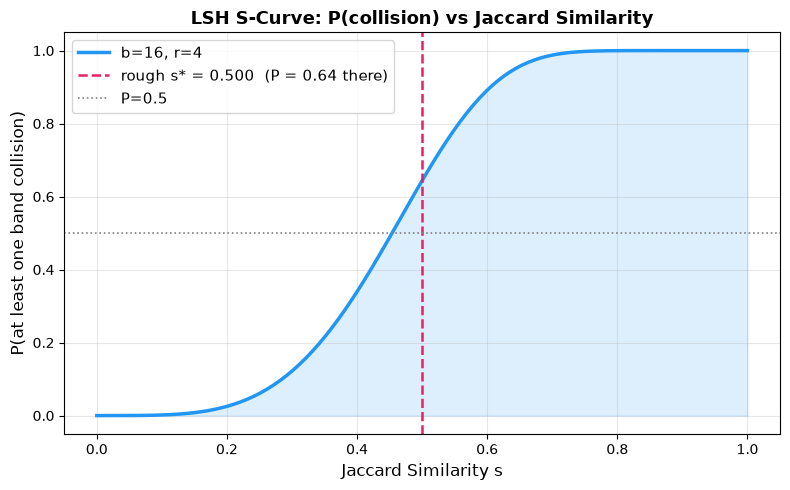


Step 1 — verify exact Jaccard, threshold J >= 0.5: 1 of 1 candidate pair(s) confirmed
Step 2 — clustering: 11 clusters, 1 of them holding more than one document
           cluster [9, 10] — labels ['high_edu', 'high_edu']
Step 3 — keep the lowest id per cluster, drop the rest: dropping [10]
Corpus: 12 documents -> 11 after deduplication

Note what this does NOT remove: Doc 5, the repeated cookie banner, survives. Its repetition
  is INSIDE a single document, so no PAIR of documents is similar. That needs Gopher's
  repetition filters (slide 11), not deduplication — two different problems that share the
  word "duplicate".


In [12]:
# ═══════════════════════════════════════════
# SECTION 10: LSH Banding — Finding Near-Duplicate Candidates  — slide 26
# Theory: Split the H=64 signature into b=16 bands of r=4 rows. Two docs collide in a band
#   if all r rows match. Collision probability for Jaccard s: P = 1 - (1 - s^r)^b.
#   The often-quoted s* ~= (1/b)^(1/r) is a ROUGH TRANSITION LOCATION, not the inflection point and
#   not the 50% point. For b=16, r=4: s* = 0.500, but P(collision | s=0.5) = 0.644 and P = 0.5 at
#   s = 0.454. Treat the S-curve as a soft ramp, never a hard cutoff.
# What this cell does: Implement LSH banding. Show which doc pairs are flagged. Plot S-curve.
# ═══════════════════════════════════════════

b, r = 16, 4
assert b * r == 64, 'b * r must equal num_hashes'

# Compute signatures for all corpus docs
all_sigs = {doc['id']: minhash_signature(doc['text']) for doc in CORPUS}

def lsh_find_candidates(signatures, b, r):
    '''Find candidate near-duplicate pairs using LSH banding.
    Returns set of (doc_id_a, doc_id_b) tuples.
    '''
    band_buckets = defaultdict(set)  # (band_idx, band_tuple) -> set of doc_ids
    for doc_id, sig in signatures.items():
        for band_idx in range(b):
            band = tuple(sig[band_idx * r : (band_idx + 1) * r].tolist())
            bucket_key = (band_idx, band)
            band_buckets[bucket_key].add(doc_id)

    candidates = set()
    for bucket, doc_ids in band_buckets.items():
        if len(doc_ids) >= 2:
            ids_list = sorted(doc_ids)
            for i in range(len(ids_list)):
                for j in range(i + 1, len(ids_list)):
                    candidates.add((ids_list[i], ids_list[j]))
    return candidates


candidates = lsh_find_candidates(all_sigs, b, r)

print(f'LSH parameters: b={b} bands, r={r} rows each (total hash functions = {b*r})')
s_star = (1 / b) ** (1 / r)
p_at_star = 1 - (1 - s_star**r)**b
print(f'Rough transition s* = (1/b)^(1/r) = (1/{b})^(1/{r}) = {s_star:.3f}')
print(f'  but P(collision | s = s*) = {p_at_star:.3f}, and P = 0.50 at s = 0.454 — a ramp, not a cutoff.')
print()
n_pairs = len(CORPUS) * (len(CORPUS) - 1) // 2
print(f'Candidate near-duplicate pairs found: {len(candidates)} (out of {n_pairs} possible pairs)')
for a_id, b_id in sorted(candidates):
    est_j = float(np.mean(all_sigs[a_id] == all_sigs[b_id]))
    exact_j = true_jaccard(CORPUS[a_id]['text'], CORPUS[b_id]['text'])
    print(f'  Doc {a_id} vs Doc {b_id}: estimated Jaccard = {est_j:.3f}, exact = {exact_j:.3f}')

# S-curve visualisation
s_vals = np.linspace(0, 1, 200)
p_vals = 1 - (1 - s_vals**r)**b

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(s_vals, p_vals, color='#2196F3', linewidth=2.5, label=f'b={b}, r={r}')
ax.axvline(s_star, color='#E91E63', linestyle='--', linewidth=1.8,
           label=f'rough s* = {s_star:.3f}  (P = {p_at_star:.2f} there)')
ax.axhline(0.5, color='gray', linestyle=':', linewidth=1.2, label='P=0.5')
ax.fill_between(s_vals, p_vals, alpha=0.15, color='#2196F3')
ax.set_title('LSH S-Curve: P(collision) vs Jaccard Similarity', fontsize=13, fontweight='bold')
ax.set_xlabel('Jaccard Similarity s', fontsize=12)
ax.set_ylabel('P(at least one band collision)', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# --- From a similarity number to an actual deletion ----------------------------------------------
# A candidate pair is not a decision yet. Three steps turn 0.656 into "drop this document":
#   1. VERIFY + THRESHOLD: recompute the EXACT shingle Jaccard of each candidate (slides 26, 29:
#      a candidate is not proof) and keep only pairs at or above J_THRESHOLD.
#   2. CLUSTER: duplication is transitive in practice — if A~B and B~C, all three carry the same
#      content. Group the surviving pairs into connected components. This is exactly what Lee et al.
#      counted in their Figure 1 (slide 20): 348M clusters of size 1, down to 280 clusters of 5000+.
#   3. KEEP-ONE POLICY: retain one document per cluster, drop the rest. WHICH one is a policy choice,
#      not a mathematical fact, and published pipelines differ. Gopher cuts at J > 0.8 on 13-word
#      shingles and REMOVES ONE AT RANDOM (Rae et al., App. A). C4 says only that it kept one copy
#      of each repeated span, without stating which. Lee et al. kept the copy in test/validation and
#      dropped the train-set one, so evaluation stayed honest. Other pipelines keep the longest or
#      cleanest. Here we keep the lowest doc id — arbitrary, but deterministic and reproducible.
J_THRESHOLD = 0.5

confirmed = [(i, j) for (i, j) in sorted(candidates)
             if true_jaccard(CORPUS[i]['text'], CORPUS[j]['text']) >= J_THRESHOLD]

parent = {doc['id']: doc['id'] for doc in CORPUS}
def find(v):
    while parent[v] != v:
        parent[v] = parent[parent[v]]
        v = parent[v]
    return v
for i, j in confirmed:
    ri, rj = find(i), find(j)
    if ri != rj:
        parent[max(ri, rj)] = min(ri, rj)

clusters = {}
for doc in CORPUS:
    clusters.setdefault(find(doc['id']), []).append(doc['id'])
multi = {root: ids for root, ids in clusters.items() if len(ids) > 1}
dropped = sorted(i for ids in multi.values() for i in sorted(ids)[1:])

print()
print(f'Step 1 — verify exact Jaccard, threshold J >= {J_THRESHOLD}: {len(confirmed)} of {len(candidates)} candidate pair(s) confirmed')
print(f'Step 2 — clustering: {len(clusters)} clusters, {len(multi)} of them holding more than one document')
for root, ids in sorted(multi.items()):
    print(f'           cluster {sorted(ids)} — labels {[CORPUS[i]["label"] for i in sorted(ids)]}')
print(f'Step 3 — keep the lowest id per cluster, drop the rest: dropping {dropped}')
print(f'Corpus: {len(CORPUS)} documents -> {len(CORPUS) - len(dropped)} after deduplication')
print()
print('Note what this does NOT remove: Doc 5, the repeated cookie banner, survives. Its repetition')
print('  is INSIDE a single document, so no PAIR of documents is similar. That needs Gopher\'s')
print('  repetition filters (slide 11), not deduplication — two different problems that share the')
print('  word "duplicate".')


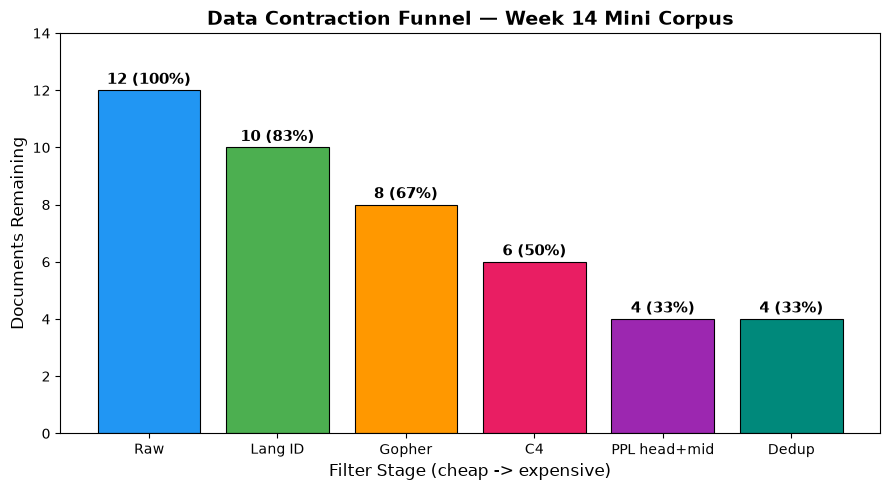

Stage            Docs  Retention
----------------------------------
Raw                12     100.0%
Lang ID            10      83.3%
Gopher              8      66.7%
C4                  6      50.0%
PPL head+mid        4      33.3%
Dedup               4      33.3%

Survivors: [(2, 'mediocre'), (3, 'mediocre'), (5, 'seo_spam'), (10, 'high_edu')]
Note how the repeated cookie banner (Doc 5) passes Lang ID, Gopher, C4, perplexity AND dedup:
  its repetition is WITHIN one document, so only Gopher's repetition rules or the neural tier
  would catch it. No single filter is sufficient.

Does the position of dedup matter? Run it one stage earlier and compare:
  C4 -> PPL -> dedup : [2, 3, 5, 10] -> [2, 3, 5, 10]   dropped nothing
  C4 -> dedup -> PPL : [1, 2, 3, 5, 9, 10] -> [1, 2, 3, 5, 9] -> [2, 3, 5]   dropped [10]
  Different survivors. Dedup keeps the LOWEST id, so it kept Doc 9 and deleted Doc 10 — and
  Doc 9 then fails the perplexity filter, while Doc 10 would have passed. The keep-one

In [13]:
# ═══════════════════════════════════════════
# SECTION 11: Filter Funnel — Retention Visualization  — slide 31
# Theory: The stages are chained in cheap-to-expensive order. Each stage only sees the survivors
#   of the previous one, so the counts form a contraction funnel.
# What this cell does: Chain Lang ID -> Gopher -> C4 -> PPL (head+middle) -> MinHash dedup and plot
#   documents remaining. The neural tier is the only stage of slide 6's funnel not implemented here.
# ═══════════════════════════════════════════

count_raw  = len(CORPUS)
count_lang = len(lang_filtered)

gopher_after_lang = [doc for doc in lang_filtered if gopher_filter(doc['text'])[0]]
c4_after_gopher   = [doc for doc in gopher_after_lang if c4_filter(doc['text'])[0]]
ppl_survivors     = [doc for doc in c4_after_gopher if doc['id'] in ppl_keep_ids]


def dedup_stage(docs, b=16, r=4, j_threshold=J_THRESHOLD):
    '''Run the Section 10 pipeline (MinHash -> LSH -> verify -> keep lowest id) on `docs`.'''
    sigs = {doc['id']: minhash_signature(doc['text']) for doc in docs}
    text_of = {doc['id']: doc['text'] for doc in docs}
    dropped = set()
    for i, j in sorted(lsh_find_candidates(sigs, b, r)):
        if true_jaccard(text_of[i], text_of[j]) >= j_threshold:   # verify exactly, as in Section 10
            dropped.add(max(i, j))                      # keep-one policy: lowest id survives
    return [doc for doc in docs if doc['id'] not in dropped], dropped


dedup_survivors, dedup_dropped = dedup_stage(ppl_survivors)

stages = ['Raw', 'Lang ID', 'Gopher', 'C4', 'PPL head+mid', 'Dedup']
counts = [count_raw, count_lang, len(gopher_after_lang), len(c4_after_gopher),
          len(ppl_survivors), len(dedup_survivors)]
colors = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63', '#9C27B0', '#00897B']

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(stages, counts, color=colors, edgecolor='black', linewidth=0.8)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
            f'{count} ({100.0 * count / count_raw:.0f}%)', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_title('Data Contraction Funnel — Week 14 Mini Corpus', fontsize=14, fontweight='bold')
ax.set_ylabel('Documents Remaining', fontsize=12)
ax.set_xlabel('Filter Stage (cheap -> expensive)', fontsize=12)
ax.set_ylim(0, count_raw + 2)
plt.tight_layout()
plt.show()

print(f'{"Stage":<14}  {"Docs":>5}  {"Retention":>9}')
print('-' * 34)
for stage, count in zip(stages, counts):
    print(f'{stage:<14}  {count:>5}  {100.0 * count / count_raw:>8.1f}%')
print()
print('Survivors:', [(d['id'], d['label']) for d in dedup_survivors])
print('Note how the repeated cookie banner (Doc 5) passes Lang ID, Gopher, C4, perplexity AND dedup:')
print('  its repetition is WITHIN one document, so only Gopher\'s repetition rules or the neural tier')
print('  would catch it. No single filter is sufficient.')

# --- Dedup is the one stage whose position changes WHO survives ------------------------------------
# Every other filter judges one document on its own, so reordering them changes cost but not the
# surviving set. Dedup looks at the whole corpus, and its keep-one policy picks a specific copy —
# a later per-document filter may then reject exactly the copy dedup chose to keep.
alt_survivors, alt_dropped = dedup_stage(c4_after_gopher)          # dedup BEFORE perplexity
alt_then_ppl = [doc for doc in alt_survivors if doc['id'] in ppl_keep_ids]
print()
print('Does the position of dedup matter? Run it one stage earlier and compare:')
print(f'  C4 -> PPL -> dedup : {[d["id"] for d in ppl_survivors]} -> '
      f'{[d["id"] for d in dedup_survivors]}   dropped {sorted(dedup_dropped) or "nothing"}')
print(f'  C4 -> dedup -> PPL : {[d["id"] for d in c4_after_gopher]} -> '
      f'{[d["id"] for d in alt_survivors]} -> {[d["id"] for d in alt_then_ppl]}   '
      f'dropped {sorted(alt_dropped)}')
print('  Different survivors. Dedup keeps the LOWEST id, so it kept Doc 9 and deleted Doc 10 — and')
print('  Doc 9 then fails the perplexity filter, while Doc 10 would have passed. The keep-one policy')
print('  (slide 29: a choice, not mathematics) decides which copy the later filters get to judge.')


## Part 2: Advanced Evaluation Metrics

Build BLEU-1, ROUGE-L, BERTScore, a biased LLM-as-Judge (with length/position demos and swap mitigation), pass@k, and RAGAS Faithfulness / Answer Relevance from scratch (slides 32-55).
No high-level wrappers — every metric is implemented from its mathematical definition.


In [14]:
# ═══════════════════════════════════════════
# SECTION 12: Why BLEU and ROUGE Fail — Quick Recap  — slide 33
# Theory: BLEU measures n-gram precision between hypothesis and reference. It fails when
#   the hypothesis is a valid paraphrase using different words — the n-gram overlap is zero
#   even though the meaning is identical. ROUGE-L swaps n-gram counting for the longest common
#   subsequence, but it is still surface matching, so it inherits the same failure.
# What this cell does: Compute BLEU-1 and ROUGE-L manually for the same pair and show the paradox.
# ═══════════════════════════════════════════

# Lower-case once, so BLEU-1 and ROUGE-L below see exactly the same tokens
# ("The" and "the" count as the same word in both). State your tokenisation when you report scores.
ref      = 'The cat sat on the mat'.lower().split()
hyp_good = 'A feline rested upon the rug'.lower().split()   # good paraphrase
hyp_bad  = 'mat the on is cat the'.lower().split()           # word salad

def unigram_precision(hyp, ref):
    '''Modified unigram precision (clipped by reference counts).'''
    ref_counts = Counter(ref)
    hyp_counts = Counter(hyp)
    clipped = sum(min(c, ref_counts.get(w, 0)) for w, c in hyp_counts.items())
    return clipped / max(1, len(hyp))


print('BLEU-1 Paradox Demonstration')
print('=' * 50)
print(f'Reference:       "{" ".join(ref)}"')
print()
for name, hyp in [('Good paraphrase', hyp_good), ('Word salad', hyp_bad)]:
    bp = min(1.0, math.exp(1 - len(ref) / len(hyp))) if len(hyp) < len(ref) else 1.0
    prec = unigram_precision(hyp, ref)
    bleu = bp * prec
    print(f'{name}:')
    print(f'  Hypothesis:  "{" ".join(hyp)}"')
    print(f'  Brevity Penalty: {bp:.3f}')
    print(f'  Unigram Precision: {prec:.3f}')
    print(f'  BLEU-1 = {bleu:.3f}')
    print()

print('PARADOX: the meaningless word salad OUTSCORES the correct paraphrase on BLEU-1')
print('(only "the" matches in the paraphrase). With BLEU-4 the paraphrase scores exactly 0:')
print('it shares no bigram, trigram or 4-gram with the reference.')
print('BERTScore (next section) resolves this using contextual embeddings.')

# --- ROUGE-L on the same pair: LCS-based, recall-oriented, still surface matching ---
def lcs_length(a, b):
    '''Length of the longest common subsequence of two token lists.'''
    table = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            table[i][j] = table[i-1][j-1] + 1 if a[i-1] == b[j-1] else max(table[i-1][j], table[i][j-1])
    return table[len(a)][len(b)]


def rouge_l(hyp, ref):
    '''ROUGE-L F1 from the LCS: recall over the reference, precision over the hypothesis.'''
    L = lcs_length(hyp, ref)
    recall, precision = L / len(ref), L / len(hyp)
    f1 = 0.0 if recall + precision == 0 else 2 * recall * precision / (recall + precision)
    return L, recall, precision, f1


print()
print('ROUGE-L on the same pair')
print('=' * 50)
for name, hyp in [('Good paraphrase', hyp_good), ('Word salad', hyp_bad)]:
    L, r, p, f1 = rouge_l(hyp, ref)   # tokens are already lower-cased above
    print(f'{name}:')
    print(f'  LCS length: {L}   Recall: {r:.3f}   Precision: {p:.3f}')
    print(f'  ROUGE-L F1 = {f1:.3f}')

print()
print('SAME PARADOX: ROUGE-L also ranks the word salad above the paraphrase')
print('(0.500 vs 0.167; BLEU-1 gave 0.833 vs 0.167). Changing the counting rule does not fix surface matching.')


BLEU-1 Paradox Demonstration
Reference:       "the cat sat on the mat"

Good paraphrase:
  Hypothesis:  "a feline rested upon the rug"
  Brevity Penalty: 1.000
  Unigram Precision: 0.167
  BLEU-1 = 0.167

Word salad:
  Hypothesis:  "mat the on is cat the"
  Brevity Penalty: 1.000
  Unigram Precision: 0.833
  BLEU-1 = 0.833

PARADOX: the meaningless word salad OUTSCORES the correct paraphrase on BLEU-1
(only "the" matches in the paraphrase). With BLEU-4 the paraphrase scores exactly 0:
it shares no bigram, trigram or 4-gram with the reference.
BERTScore (next section) resolves this using contextual embeddings.

ROUGE-L on the same pair
Good paraphrase:
  LCS length: 1   Recall: 0.167   Precision: 0.167
  ROUGE-L F1 = 0.167
Word salad:
  LCS length: 3   Recall: 0.500   Precision: 0.500
  ROUGE-L F1 = 0.500

SAME PARADOX: ROUGE-L also ranks the word salad above the paraphrase
(0.500 vs 0.167; BLEU-1 gave 0.833 vs 0.167). Changing the counting rule does not fix surface matching.


In [15]:
# ═══════════════════════════════════════════
# SECTION 13: BERTScore — Token Embeddings  — slides 34 and 36
# Theory: BERTScore embeds all tokens of candidate and reference using a contextual LM.
#   The embedding matrix C in R^{n x d} and R in R^{m x d} capture contextual meaning
#   rather than surface form.
# What this cell does: Load distilbert-base-uncased. Tokenise and embed candidate and
#   reference. Print embedding shapes.
# ═══════════════════════════════════════════

from transformers import AutoModel

bertscore_model_name = 'distilbert-base-uncased'
bs_tokenizer = AutoTokenizer.from_pretrained(bertscore_model_name)
bs_model = AutoModel.from_pretrained(bertscore_model_name).to(device)
bs_model.eval()

candidate = 'A feline rested upon the rug'
reference = 'The cat sat on the mat'

print(f'Candidate: "{candidate}"')
print(f'Reference: "{reference}"')
print()

def get_embeddings(text, tokenizer, model, device):
    '''Embed all tokens of text using a BERT-style model.
    Returns tensor of shape [seq_len, hidden_dim].
    '''
    inputs = tokenizer(text, return_tensors='pt', add_special_tokens=False).to(device)
    with torch.no_grad():
        outputs = model(**inputs)
    embeddings = outputs.last_hidden_state[0]  # [seq_len, hidden_dim]
    return embeddings


cand_emb = get_embeddings(candidate, bs_tokenizer, bs_model, device)
ref_emb  = get_embeddings(reference,  bs_tokenizer, bs_model, device)

print(f'cand_emb shape: {tuple(cand_emb.shape)}')  # Expected: (n, 768)
print(f'ref_emb  shape: {tuple(ref_emb.shape)}')   # Expected: (m, 768)

cand_tokens = bs_tokenizer.tokenize(candidate)
ref_tokens  = bs_tokenizer.tokenize(reference)

print()
print(f'Candidate tokens ({len(cand_tokens)}): {cand_tokens}')
print(f'Reference  tokens ({len(ref_tokens)}): {ref_tokens}')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Candidate: "A feline rested upon the rug"
Reference: "The cat sat on the mat"

cand_emb shape: (7, 768)
ref_emb  shape: (6, 768)

Candidate tokens (7): ['a', 'fe', '##line', 'rested', 'upon', 'the', 'rug']
Reference  tokens (6): ['the', 'cat', 'sat', 'on', 'the', 'mat']


S shape: (7, 6)


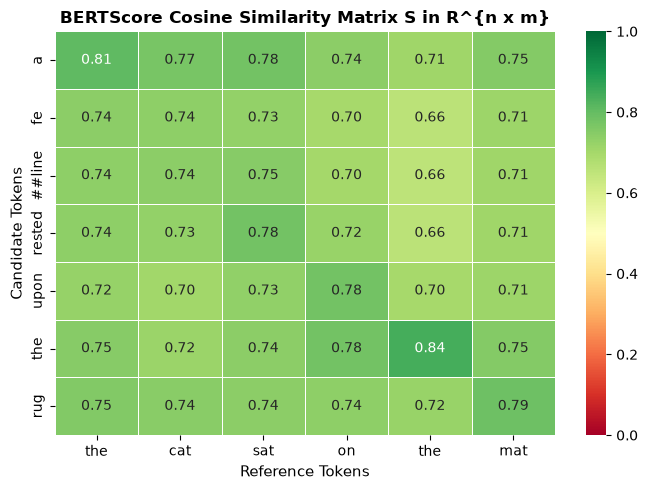


Rows = candidate tokens, Columns = reference tokens.
High values on the diagonal or near-synonyms indicate semantic alignment.


In [16]:
# ═══════════════════════════════════════════
# SECTION 14: BERTScore — Cosine Similarity Matrix  — slide 34
# Theory: S[i,j] = cos(c_i, r_j) = (c_i . r_j) / (||c_i|| ||r_j||).
#   Matrix S in R^{n x m} captures pairwise semantic similarity between every candidate
#   token and every reference token.
# What this cell does: Compute the n x m cosine similarity matrix S. Visualise as a heatmap.
# ═══════════════════════════════════════════

# L2-normalise each token embedding
cand_norm = cand_emb / cand_emb.norm(dim=1, keepdim=True)
ref_norm  = ref_emb  / ref_emb.norm(dim=1, keepdim=True)

# Compute cosine similarity matrix via matrix multiplication
S = cand_norm @ ref_norm.T  # [n, m]
S_np = S.cpu().float().numpy()

print(f'S shape: {S_np.shape}')  # Expected: [n, m] e.g. [6, 6]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    S_np,
    annot=True,
    fmt='.2f',
    xticklabels=ref_tokens,
    yticklabels=cand_tokens,
    cmap='RdYlGn',
    vmin=0,
    vmax=1,
    ax=ax,
    linewidths=0.5
)
ax.set_title('BERTScore Cosine Similarity Matrix S in R^{n x m}', fontsize=12, fontweight='bold')
ax.set_xlabel('Reference Tokens', fontsize=11)
ax.set_ylabel('Candidate Tokens', fontsize=11)
plt.tight_layout()
plt.show()

print()
print('Rows = candidate tokens, Columns = reference tokens.')
print('High values on the diagonal or near-synonyms indicate semantic alignment.')

In [17]:
# ═══════════════════════════════════════════
# SECTION 15: BERTScore — Greedy P/R/F1 + IDF Weighting  — slides 35-36
# Theory: Precision: each candidate token greedily matched to most similar reference token.
#   Recall: symmetric. F1: harmonic mean. IDF weights rare tokens more: w_i = -log(df_i/N).
# What this cell does: Compute BERTScore P, R, F1 with and without IDF weighting.
# ═══════════════════════════════════════════

# --- Uniform BERTScore ---
P_BERT = float(S_np.max(axis=1).mean())   # each row: best match over all reference tokens
R_BERT = float(S_np.max(axis=0).mean())   # each col: best match over all candidate tokens
F_BERT = 2 * P_BERT * R_BERT / (P_BERT + R_BERT)

print('--- Uniform BERTScore ---')
print(f'BERTScore Precision: {P_BERT:.4f}')
print(f'BERTScore Recall:    {R_BERT:.4f}')
print(f'BERTScore F1:        {F_BERT:.4f}')

# --- IDF-weighted BERTScore ---
# Mock IDF values: rare/meaningful words get high IDF, function words get low IDF
mock_idf = {
    'a': 0.2,    'feline': 3.8, 'rested': 3.5,
    'upon': 2.1, 'the': 0.1,    'rug': 3.2,
    'cat': 3.1,  'sat': 3.0,    'on': 0.3,
    'mat': 3.3,  '##sted': 3.5, '##ine': 3.8,
    'fe': 3.7,   'rest': 3.4,   'up': 2.0,
    'ru': 3.1,   '##g': 2.9
}

cand_idf = np.array([mock_idf.get(t, 1.0) for t in cand_tokens])
ref_idf  = np.array([mock_idf.get(t, 1.0) for t in ref_tokens])

P_idf = float((cand_idf * S_np.max(axis=1)).sum() / cand_idf.sum())
R_idf = float((ref_idf  * S_np.max(axis=0)).sum() / ref_idf.sum())
F_idf = 2 * P_idf * R_idf / (P_idf + R_idf)

print()
print('--- IDF-weighted BERTScore ---')
print(f'IDF-weighted P/R/F1: {P_idf:.4f} / {R_idf:.4f} / {F_idf:.4f}')
print()
print('(Compare: BLEU-1 for this paraphrase = 0.167 and BLEU-4 = 0 — BERTScore correctly rewards the paraphrase)')
print('These are RAW cosine scores; the reference implementation rescales by a random-pair baseline.')
print('IDF weighting boosts the contribution of rare, content-bearing tokens (feline, rug, mat).')

# --- Control: score the WORD SALAD too ---------------------------------------
# BLEU-1 ranked the word salad ABOVE the paraphrase (Section 12). Does BERTScore?
# Same lower-cased tokens as Section 12; both hypotheses have the reference's length, so BP = 1.
bleu1_good, bleu1_salad = unigram_precision(hyp_good, ref), unigram_precision(hyp_bad, ref)
salad = 'mat the on is cat the'
salad_emb = get_embeddings(salad, bs_tokenizer, bs_model, device)
salad_norm = salad_emb / salad_emb.norm(dim=1, keepdim=True)
S_salad = (salad_norm @ ref_norm.T).cpu().float().numpy()
P_s = float(S_salad.max(axis=1).mean())
R_s = float(S_salad.max(axis=0).mean())
F_s = 2 * P_s * R_s / (P_s + R_s)

print()
print('--- Ranking check: paraphrase vs word salad (same reference) ---')
print(f'{"hypothesis":<22} {"BLEU-1":>7} {"BERTScore F1":>13}')
print(f'{"A feline rested...":<22} {bleu1_good:>7.3f} {F_BERT:>13.4f}')
print(f'{"mat the on is cat the":<22} {bleu1_salad:>7.3f} {F_s:>13.4f}')
print()
print('BLEU-1 ranks the word salad FIRST. BERTScore ranks the paraphrase first — that ordering,')
print('not the size of the gap, is the evidence. The two metrics are on different scales, so')
print('"0.79 vs 0.17" is not a like-for-like comparison.')
print()
print('Caveat: BERTScore rewards being on-topic, not being correct. A fluent sentence that')
print('contradicts the reference can still score highly — it is not a factuality check.')


--- Uniform BERTScore ---
BERTScore Precision: 0.7838
BERTScore Recall:    0.7952
BERTScore F1:        0.7895

--- IDF-weighted BERTScore ---
IDF-weighted P/R/F1: 0.7700 / 0.7817 / 0.7758

(Compare: BLEU-1 for this paraphrase = 0.167 and BLEU-4 = 0 — BERTScore correctly rewards the paraphrase)
These are RAW cosine scores; the reference implementation rescales by a random-pair baseline.
IDF weighting boosts the contribution of rare, content-bearing tokens (feline, rug, mat).

--- Ranking check: paraphrase vs word salad (same reference) ---
hypothesis              BLEU-1  BERTScore F1
A feline rested...       0.167        0.7895
mat the on is cat the    0.833        0.6732

BLEU-1 ranks the word salad FIRST. BERTScore ranks the paraphrase first — that ordering,
not the size of the gap, is the evidence. The two metrics are on different scales, so
"0.79 vs 0.17" is not a like-for-like comparison.

Caveat: BERTScore rewards being on-topic, not being correct. A fluent sentence that
contradic

In [18]:
# ═══════════════════════════════════════════
# SECTION 16: LLM-as-Judge — Mock Judge Framework  — slides 38-40
# Theory: MT-Bench uses GPT-4 as judge. We simulate with a deterministic mock judge
#   that scores responses on length and keyword match, plus a small bonus for position A.
#   Both biases are documented in Zheng et al. (2023); this lets us reproduce them without an API key.
# What this cell does: Implement mock_judge(). Build 6 test cases.
# ═══════════════════════════════════════════

POSITION_A_BONUS = 4.0   # primacy effect: the first-shown answer gets a small head start

def mock_judge(question, resp_a, resp_b):
    '''Deterministic mock LLM judge.
    Intentionally LENGTH-BIASED and POSITION-BIASED to demonstrate two known failure modes.
    Returns (winner: str in {"A","B","tie"}, margin: float).
    '''
    # Score = 0.6 * word_count + 10 * question-word overlap (+ position bonus for A)
    # Token-exact matching: a substring test would count "explain" inside "explained" and
    # silently confound the length demo in SECTION 18.
    def toks(s): return set(re.findall(r'[a-z]+', s.lower()))
    q_words = toks(question)
    a_tok, b_tok = toks(resp_a), toks(resp_b)
    score_a = (len(resp_a.split()) * 0.6 + len(q_words & a_tok) * 10 + POSITION_A_BONUS)
    score_b = (len(resp_b.split()) * 0.6 + len(q_words & b_tok) * 10)

    if score_a > score_b:
        return 'A', score_a - score_b
    elif score_b > score_a:
        return 'B', score_b - score_a
    else:
        return 'tie', 0.0


TEST_CASES = [
    {
        'question': 'What is backpropagation?',
        'resp_a': ('Backpropagation computes gradients of the loss with respect to each '
                   'parameter by applying the chain rule layer by layer.'),
        'resp_b': ('Backpropagation is an algorithm. It is used in neural networks. '
                   'It helps the model learn. The model updates its weights. '
                   'This process is repeated many times until the model converges. '
                   'It is a very important algorithm in deep learning and machine learning.'),
        'note': 'A is concise+correct, B is verbose+shallow'
    },
    {
        'question': 'Explain the softmax function.',
        'resp_a': 'softmax(z_i) = exp(z_i) / sum_j exp(z_j). It converts logits to a probability distribution.',
        'resp_b': ('The softmax function takes a vector of real numbers and squashes them into '
                   'a probability distribution so that all values are positive and sum to one. '
                   'It is computed by taking the exponential of each input and dividing by the '
                   'sum of all exponentials. This is used in the final layer of classification models.'),
        'note': 'A is precise formula, B is longer prose'
    },
    {
        'question': 'What is overfitting?',
        'resp_a': 'Overfitting occurs when a model memorises the training data and fails to generalise to unseen data.',
        'resp_b': ('Overfitting is a very common problem in machine learning. '
                   'When a model overfits it learns the training data too well. '
                   'This is a big problem. You can fix it with regularisation. '
                   'Dropout also helps. Cross-validation is another technique. '
                   'Early stopping is yet another approach. Data augmentation can help too.'),
        'note': 'A is precise, B is verbose list'
    },
    {
        'question': 'Define precision and recall.',
        'resp_a': 'Precision = TP/(TP+FP). Recall = TP/(TP+FN). Precision measures exactness, recall measures completeness.',
        'resp_b': ('Precision and recall are two important metrics. '
                   'Precision is the fraction of retrieved documents that are relevant. '
                   'Recall is the fraction of relevant documents that were retrieved. '
                   'High precision means few false positives. High recall means few false negatives. '
                   'The F1 score is the harmonic mean of precision and recall.'),
        'note': 'A is formula, B is longer explanation'
    },
    {
        'question': 'What is a transformer?',
        'resp_a': ('The Transformer (Vaswani et al. 2017) replaces recurrence with self-attention, '
                   'allowing parallel computation over full sequences.'),
        'resp_b': ('A transformer is a deep learning architecture. It was introduced in 2017. '
                   'It uses attention mechanisms. It does not use recurrent layers. '
                   'It can process sequences in parallel. It is used in many NLP tasks today. '
                   'GPT and BERT are both based on the transformer architecture.'),
        'note': 'A is precise+attributed, B is verbose'
    },
    {
        'question': 'What is dropout?',
        'resp_a': ('Dropout randomly zeroes a fraction of activations during training, which '
                   'discourages co-adaptation between hidden units and acts as a useful regulariser.'),
        'resp_b': ('Dropout randomly disables a fraction of units in each training step, which '
                   'forces the network to spread knowledge and reduce overfitting.'),
        'note': 'A and B are equally good and the SAME LENGTH — a fair judge should say tie'
    }
]

print('Mock Judge Evaluation on 6 Test Cases')
print('=' * 70)
for i, tc in enumerate(TEST_CASES):
    winner, margin = mock_judge(tc['question'], tc['resp_a'], tc['resp_b'])
    print(f'Case {i+1}: {tc["question"]}')
    print(f'  ({tc["note"]})')
    print(f'  Judge verdict: {winner} wins (margin={margin:.1f})')
    print()
for i, tc in enumerate(TEST_CASES):
    print(f'  Case {i+1}: A = {len(tc["resp_a"].split())} words, B = {len(tc["resp_b"].split())} words')
print()
print('Cases 1-5: the longer answer wins every time (length bias).')
print('Case 6: equal quality AND equal length, yet A wins — that is the position bonus alone.')
print()
print('Both biases here are PROGRAMMED INTO the mock judge. This shows what the bias looks like,')
print('it does not measure a real model. The measured rates for real judges are on slides 39-40.')


Mock Judge Evaluation on 6 Test Cases
Case 1: What is backpropagation?
  (A is concise+correct, B is verbose+shallow)
  Judge verdict: B wins (margin=19.8)

Case 2: Explain the softmax function.
  (A is precise formula, B is longer prose)
  Judge verdict: B wins (margin=40.6)

Case 3: What is overfitting?
  (A is precise, B is verbose list)
  Judge verdict: B wins (margin=25.8)

Case 4: Define precision and recall.
  (A is formula, B is longer explanation)
  Judge verdict: B wins (margin=28.8)

Case 5: What is a transformer?
  (A is precise+attributed, B is verbose)
  Judge verdict: B wins (margin=34.0)

Case 6: What is dropout?
  (A and B are equally good and the SAME LENGTH — a fair judge should say tie)
  Judge verdict: A wins (margin=4.0)

  Case 1: A = 19 words, B = 42 words
  Case 2: A = 13 words, B = 54 words
  Case 3: A = 16 words, B = 49 words
  Case 4: A = 12 words, B = 50 words
  Case 5: A = 16 words, B = 46 words
  Case 6: A = 21 words, B = 21 words

Cases 1-5: the longer a

In [19]:
# ═══════════════════════════════════════════
# SECTION 17: Length Bias Demonstration  — slide 39
# Theory: Verbosity bias — judges prefer longer responses even when content is equivalent.
#   Zheng et al. (2023) padded answers with rephrased repeats of their own list items and measured
#   how often the judge preferred the padded version (Claude-v1 91%, GPT-3.5 91%, GPT-4 8.7%).
# What this cell does: Pad a concise response with 0-4 filler sentences and show that the judge's
#   margin in favour of the padded version grows with padding, although no information was added.
# ═══════════════════════════════════════════

RESPONSE_CONCISE = ('Gradient descent minimises loss by moving parameters in the direction '
                    'of steepest descent. Step size is controlled by the learning rate.')
# Filler carries no information AND no question keywords, so the only thing that changes
# between rows below is LENGTH. (An earlier version leaked the word "explain" into the filler,
# which added keyword points and confounded the demonstration.)
FILLERS = [
    ' Certainly, this is a truly great point to raise.',
    ' Let me now elaborate a little further on that topic.',
    ' In summary, as noted above, the procedure involves repeated updates.',
    ' I do hope that this thorough write-up proves helpful to you.',
]
QUESTION = 'Explain gradient descent.'

print(f'Question: "{QUESTION}"')
print(f'Concise response ({len(RESPONSE_CONCISE.split())} words): "{RESPONSE_CONCISE}"')
print()
print(f'{"# filler sentences":>18}  {"words":>5}  {"winner":>6}  {"margin":>6}')
print('-' * 45)
for n_fill in range(len(FILLERS) + 1):
    padded = RESPONSE_CONCISE + ''.join(FILLERS[:n_fill])
    winner, margin = mock_judge(QUESTION, RESPONSE_CONCISE, padded)   # A = concise, B = padded
    label = {'A': 'concise', 'B': 'padded', 'tie': 'tie'}[winner]
    print(f'{n_fill:>18}  {len(padded.split()):>5}  {label:>6}  {margin:>6.1f}')

print()
print(f'Each filler sentence adds words but no question keywords, so every step of the margin is')
print(f'attributable to length alone (0.6 points per word).')
print('Zero filler: identical texts, yet "concise" (position A) wins by the position bonus alone.')
print('Every filler sentence adds words but no information, and the margin for the padded version grows.')
print('Implication: judges that reward surface statistics over-reward verbosity (Goodhart\'s law).')
print('Mitigations: length-controlled scoring (AlpacaEval-LC), rubric instructions, reference-based metrics.')


Question: "Explain gradient descent."
Concise response (21 words): "Gradient descent minimises loss by moving parameters in the direction of steepest descent. Step size is controlled by the learning rate."

# filler sentences  words  winner  margin
---------------------------------------------
                 0     21  concise     4.0
                 1     30  padded     1.4
                 2     40  padded     7.4
                 3     50  padded    13.4
                 4     61  padded    20.0

Each filler sentence adds words but no question keywords, so every step of the margin is
attributable to length alone (0.6 points per word).
Zero filler: identical texts, yet "concise" (position A) wins by the position bonus alone.
Every filler sentence adds words but no information, and the margin for the padded version grows.
Implication: judges that reward surface statistics over-reward verbosity (Goodhart's law).
Mitigations: length-controlled scoring (AlpacaEval-LC), rubric instructi

In [20]:
# ═══════════════════════════════════════════
# SECTION 18: Positional Bias + Swap Mitigation  — slide 40
# Theory: Positional bias — judges prefer the response in Position A (primacy effect).
#   Mitigation: run in both orders (A-B and B-A); declare winner only if consistent.
# What this cell does: Run mock_judge in both orderings. Compute swap disagreement rate.
# ═══════════════════════════════════════════

def judge_with_swap(question, resp1, resp2):
    '''Run judge in both orderings. Return consistent winner or tie_or_inconsistent.'''
    winner_ab, _ = mock_judge(question, resp1, resp2)
    winner_ba, _ = mock_judge(question, resp2, resp1)

    # In AB order: A=resp1, B=resp2
    # In BA order: A=resp2, B=resp1
    if winner_ab == 'A' and winner_ba == 'B':
        return 'resp1_wins'          # consistent: resp1 wins in both orderings
    elif winner_ab == 'B' and winner_ba == 'A':
        return 'resp2_wins'          # consistent: resp2 wins in both orderings
    else:
        return 'tie_or_inconsistent' # one ordering gives tie, or outcomes disagree


print('Swap Consistency Test on 6 Test Cases')
print('=' * 65)
print(f'{"Case":>5}  {"No-swap winner":>15}  {"Swap result":>25}  {"Consistent?":>12}')
print('-' * 65)

inconsistencies = 0
for i, tc in enumerate(TEST_CASES):
    winner_noswap, _ = mock_judge(tc['question'], tc['resp_a'], tc['resp_b'])
    swap_result = judge_with_swap(tc['question'], tc['resp_a'], tc['resp_b'])
    consistent = swap_result in ('resp1_wins', 'resp2_wins')
    if not consistent:
        inconsistencies += 1
    consistent_str = 'YES' if consistent else 'NO (positional bias)'
    print(f'{i+1:>5}  {winner_noswap:>15}  {swap_result:>25}  {consistent_str:>12}')

print()
print(f'Swap disagreement rate: {inconsistencies}/{len(TEST_CASES)} cases reversed when order was swapped.')
print('After mitigation: only consistent wins are declared. A pair whose two orders disagree is')
print('  "inconsistent"; scoring it as a tie (as we do here) is an aggregation policy, not a')
print('  measurement (slide 40).')
print()
print('Cases 1-5: the length gap is far larger than the position bonus, so the verdict survives the swap.')
print('Case 6: equally good answers — whichever is shown first wins, so the two orderings disagree;')
print('  swap mitigation flags it as inconsistent (scored here as a tie) instead of crowning a spurious winner.')
print('Real judges (Zheng et al. 2023, Table 2): GPT-4 consistent on 65% of swapped pairs, Claude-v1 on 24%.')

Swap Consistency Test on 6 Test Cases
 Case   No-swap winner                Swap result   Consistent?
-----------------------------------------------------------------
    1                B                 resp2_wins           YES
    2                B                 resp2_wins           YES
    3                B                 resp2_wins           YES
    4                B                 resp2_wins           YES
    5                B                 resp2_wins           YES
    6                A        tie_or_inconsistent  NO (positional bias)

Swap disagreement rate: 1/6 cases reversed when order was swapped.
After mitigation: only consistent wins are declared. A pair whose two orders disagree is
  "inconsistent"; scoring it as a tie (as we do here) is an aggregation policy, not a
  measurement (slide 40).

Cases 1-5: the length gap is far larger than the position bonus, so the verdict survives the swap.
Case 6: equally good answers — whichever is shown first wins, so the tw

In [21]:
# ═══════════════════════════════════════════
# SECTION 19: pass@k Estimator  — slide 44
# Theory: pass@k = 1 - C(n-c, k) / C(n, k) where n=total samples, c=correct samples,
#   k=target attempts. This is an unbiased estimator of the probability that at least
#   one correct solution appears in k random draws without replacement.
# What this cell does: Implement pass_at_k(). Demo on coding problem scenarios.
# ═══════════════════════════════════════════

def pass_at_k(n, c, k):
    '''Unbiased estimator of pass@k.
    n: total samples generated
    c: number of correct samples (0 <= c <= n)
    k: number of allowed attempts (1 <= k <= n)
    Returns probability that at least one of k samples drawn WITHOUT replacement is correct.
    Note: pass@k for different k are different quantities, not more precise versions of one number.
    Raising n reduces the VARIANCE of the estimate for a given k.
    '''
    if not (isinstance(n, int) and isinstance(c, int) and isinstance(k, int)):
        raise TypeError('pass_at_k expects integers')
    if not (0 <= c <= n) or not (1 <= k <= n):
        raise ValueError(f'need 0 <= c <= n and 1 <= k <= n; got n={n}, c={c}, k={k}')
    if c == 0:
        return 0.0
    if n - c < k:
        return 1.0
    # Use math.comb (exact integer combinatorics, no overflow)
    return 1.0 - math.comb(n - c, k) / math.comb(n, k)


scenarios = [
    ('Easy problem',    200, 150),
    ('Medium problem',  200,  50),
    ('Hard problem',    200,  10),
    ('Very hard',       200,   2),
    ('Nearly unsolvable', 200, 1),
]

print(f'{"Scenario":<22}  {"n":>5}  {"c":>5}  {"c/n":>6}  '
      f'{"pass@1":>8}  {"pass@10":>8}  {"pass@100":>9}')
print('-' * 72)

for name, n, c in scenarios:
    p1   = pass_at_k(n, c, 1)
    p10  = pass_at_k(n, c, 10)
    p100 = pass_at_k(n, c, 100)
    print(f'{name:<22}  {n:>5}  {c:>5}  {c/n:>6.3f}  '
          f'{p1:>8.3f}  {p10:>8.3f}  {p100:>9.3f}')

print()
print('Insight: Even for very hard problems (c/n=0.005),')
print('  pass@100 is still non-trivial. This motivates sampling-based evaluation')
print('  in code generation benchmarks (HumanEval, MBPP). SWE-bench, by contrast, reports the')
print('  percentage of issues resolved, usually from one attempt per issue (slide 50).')

Scenario                    n      c     c/n    pass@1   pass@10   pass@100
------------------------------------------------------------------------
Easy problem              200    150   0.750     0.750     1.000      1.000
Medium problem            200     50   0.250     0.250     0.948      1.000
Hard problem              200     10   0.050     0.050     0.409      0.999
Very hard                 200      2   0.010     0.010     0.098      0.751
Nearly unsolvable         200      1   0.005     0.005     0.050      0.500

Insight: Even for very hard problems (c/n=0.005),
  pass@100 is still non-trivial. This motivates sampling-based evaluation
  in code generation benchmarks (HumanEval, MBPP). SWE-bench, by contrast, reports the
  percentage of issues resolved, usually from one attempt per issue (slide 50).


In [22]:
# ═══════════════════════════════════════════
# SECTION 20: RAGAS Faithfulness from Scratch  — slide 53
# Theory: Faithfulness = |claims in answer supported by context| / |total claims in answer|.
#   RAGAS uses an LLM to split the answer into atomic claims and to check entailment against the
#   context. Here we use a cheap PROXY: split on sentences, drop stop words, and call a claim
#   supported if (a) every number in the claim appears in the context and (b) at least half of its
#   content words do. Rule (a) is what catches "500 metres" and "1750".
# What this cell does: Implement faithfulness_score(answer, context) and contrast a faithful vs a
#   hallucinated answer.
# ═══════════════════════════════════════════

STOP_WORDS = {'the', 'a', 'an', 'is', 'was', 'are', 'were', 'be', 'it', 'its', 'in', 'on', 'of', 'and',
              'to', 'by', 'for', 'with', 'at', 'as', 'that', 'this', 'has', 'have', 'had'}

def extract_claims(text):
    '''Split text into atomic claims on sentence boundaries (keep sentences longer than 10 chars).'''
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+', text) if len(s.strip()) > 10]


def content_words(text):
    return set(re.findall(r'\w+', text.lower())) - STOP_WORDS


def claim_supported(claim, context, threshold=0.5):
    '''Proxy for LLM entailment: numbers must all appear in the context, and >= threshold of the
    claim's content words must appear in the context.'''
    cw = content_words(claim)
    ctx = set(re.findall(r'\w+', context.lower()))
    if not cw:
        return False
    numbers = {w for w in cw if w.isdigit()}
    if numbers and not numbers <= ctx:      # a number not in the context => unsupported
        return False
    return len(cw & ctx) / len(cw) >= threshold


def faithfulness_score(answer, context):
    '''Fraction of claims supported by the context. Returns float in [0, 1].'''
    claims = extract_claims(answer)
    if not claims:
        return 0.0
    return sum(claim_supported(c, context) for c in claims) / len(claims)


context = 'The Eiffel Tower is 330 metres tall and was built in 1889 in Paris, France.'
faithful_answer     = 'The Eiffel Tower stands 330 metres tall. It was constructed in 1889.'
hallucinated_answer = 'The Eiffel Tower is 500 metres tall. It was built in 1750 in London.'

print('RAGAS Faithfulness Demo (keyword + number proxy)')
print('=' * 60)
print(f'Context: "{context}"')
print()
for name, answer in [('Faithful answer', faithful_answer), ('Hallucinated answer', hallucinated_answer)]:
    claims = extract_claims(answer)
    print(f'{name}:  "{answer}"')
    for claim in claims:
        status = 'SUPPORTED  ' if claim_supported(claim, context) else 'UNSUPPORTED'
        print(f'    [{status}] "{claim}"')
    print(f'  Faithfulness score: {faithfulness_score(answer, context):.3f}')
    print()

print('Limits of the proxy: it cannot see negation or paraphrase ("The tower is NOT in Paris" would pass).')
print('Production RAGAS asks an LLM "does the context imply this claim?" for every claim — semantically')
print('precise but costly. Calibrate any cheap proxy against LLM/human judgments on a sample.')


RAGAS Faithfulness Demo (keyword + number proxy)
Context: "The Eiffel Tower is 330 metres tall and was built in 1889 in Paris, France."

Faithful answer:  "The Eiffel Tower stands 330 metres tall. It was constructed in 1889."
    [SUPPORTED  ] "The Eiffel Tower stands 330 metres tall."
    [SUPPORTED  ] "It was constructed in 1889."
  Faithfulness score: 1.000

Hallucinated answer:  "The Eiffel Tower is 500 metres tall. It was built in 1750 in London."
    [UNSUPPORTED] "The Eiffel Tower is 500 metres tall."
    [UNSUPPORTED] "It was built in 1750 in London."
  Faithfulness score: 0.000

Limits of the proxy: it cannot see negation or paraphrase ("The tower is NOT in Paris" would pass).
Production RAGAS asks an LLM "does the context imply this claim?" for every claim — semantically
precise but costly. Calibrate any cheap proxy against LLM/human judgments on a sample.


In [23]:
# ═══════════════════════════════════════════
# SECTION 21: RAGAS Answer Relevance  — slide 53
# Theory: Answer Relevance measures if the answer addresses the question. Method: embed
#   the answer, reverse-generate hypothetical questions from it, check if those questions
#   embeddings are close to the original question embedding. We proxy this with direct
#   cosine similarity between question and answer embeddings.
# What this cell does: Simulate Answer Relevance using sentence embedding cosine similarity.
# ═══════════════════════════════════════════

def embed_text(text):
    '''Mean-pool BERT token embeddings into a single unit-norm sentence vector.
    Returns normalised tensor of shape [768].
    '''
    inputs = bs_tokenizer(
        text,
        return_tensors='pt',
        truncation=True,
        max_length=128
    ).to(device)
    with torch.no_grad():
        out = bs_model(**inputs)
    emb = out.last_hidden_state[0].mean(dim=0)  # mean pool -> [768]
    return emb / emb.norm()


question = 'What is gradient descent?'
relevant_answer = ('Gradient descent is an optimisation algorithm that minimises loss by '
                   'iteratively updating parameters in the direction of the negative gradient.')
irrelevant_answer = ('Paris is the capital of France and has many famous landmarks '
                     'like the Eiffel Tower.')

q_emb = embed_text(question)
r_emb = embed_text(relevant_answer)
i_emb = embed_text(irrelevant_answer)

sim_relevant   = float((q_emb * r_emb).sum().item())
sim_irrelevant = float((q_emb * i_emb).sum().item())

print('RAGAS Answer Relevance (Cosine Similarity Proxy)')
print('=' * 55)
print(f'Question: "{question}"')
print()
print(f'Relevant answer:   "{relevant_answer[:80]}..."')
print(f'Relevance score:    {sim_relevant:.4f}')
print()
print(f'Irrelevant answer: "{irrelevant_answer}"')
print(f'Relevance score:    {sim_irrelevant:.4f}')
print()
print('Higher = more relevant to question.')
print()
delta = sim_relevant - sim_irrelevant
print(f'Delta (relevant - irrelevant): {delta:.4f}')
if delta > 0:
    print('Correct: relevant answer scores higher than irrelevant answer.')
else:
    print('Note: embedding similarity is approximate — topic proximity may conflate scores.')
print()
print('Production RAGAS uses an LLM to generate reverse questions from the answer,')
print('then measures how close those reverse questions are to the original question.')

RAGAS Answer Relevance (Cosine Similarity Proxy)
Question: "What is gradient descent?"

Relevant answer:   "Gradient descent is an optimisation algorithm that minimises loss by iteratively..."
Relevance score:    0.6891

Irrelevant answer: "Paris is the capital of France and has many famous landmarks like the Eiffel Tower."
Relevance score:    0.5248

Higher = more relevant to question.

Delta (relevant - irrelevant): 0.1643
Correct: relevant answer scores higher than irrelevant answer.

Production RAGAS uses an LLM to generate reverse questions from the answer,
then measures how close those reverse questions are to the original question.


In [24]:
# ═══════════════════════════════════════════
# SECTION 22: Week 14 Concept Map Summary
# What this cell does: Print an ASCII concept map summarising Part 1 and Part 2, and list the sections.
# ═══════════════════════════════════════════

concept_map = '''
╔══════════════════════════════════╦══════════════════════════════════╗
║  PART 1: DATA FACTORY            ║  PART 2: EVALUATION SUITE        ║
╠══════════════════════════════════╬══════════════════════════════════╣
║  Common Crawl (WARC / WET)       ║  Era 1: BLEU / ROUGE             ║
║    ↓ Language ID (fastText)      ║    ↓ surface string matching     ║
║    ↓ Gopher + C4 heuristics      ║  Era 2: BERTScore / Arena / Judge║
║    ↓ Perplexity (KenLM, CCNet)   ║    ↓ semantic + preference       ║
║    ↓ SHA-256 + MinHash/LSH dedup ║  Era 3: LiveBench / SWE-bench    ║
║    ↓ Edu classifier (FineWeb-Edu)║    ↓ dynamic + capability-spec.  ║
║  Clean corpus (1.3T tokens)      ║  Production: RAGAS / DeepEval    ║
╚══════════════════════════════════╩══════════════════════════════════╝
'''
print(concept_map)

summary_rows = [
    ('Part 1', 'Language ID',              'Non-ASCII fraction + function words, 0.65 threshold (slide 7)'),
    ('Part 1', 'Tokenizer Efficiency',     'TPC on EN/TH, [UNK] check (slides 8-9)'),
    ('Part 1', 'Gopher Rules',             '5 rules incl. 80% alpha-word ratio (slide 11)'),
    ('Part 1', 'C4 Rules',                 'Page + sentence rules, curly-brace collateral damage (slide 12)'),
    ('Part 1', 'Perplexity Filter',        'DistilGPT-2 PPL, head/middle/tail buckets, CCNet trap (slides 14-15)'),
    ('Part 1', 'SHA-256 Exact Dedup',      'Hash-set lookup (slide 21)'),
    ('Part 1', 'MinHash Signatures',       'Universal hashing, H=64, k=3 (slide 23)'),
    ('Part 1', 'Jaccard Estimation',       'Doc 9 vs 10: 0.656 est vs 0.662 true (slides 23, 29)'),
    ('Part 1', 'LSH Banding',              'b=16, r=4, S-curve (slides 26-29)'),
    ('Part 1', 'Filter Funnel',            'Retention chart, cheap -> expensive (slides 6, 31)'),
    ('Part 2', 'BLEU/ROUGE Paradox',       'Paraphrase vs word salad: BLEU-1 0.17 vs 0.83, ROUGE-L 0.17 vs 0.50, lower-cased (slide 33)'),
    ('Part 2', 'BERTScore',                'Embeddings, heatmap, greedy P/R/F1, IDF (slides 34-36)'),
    ('Part 2', 'LLM-as-Judge Mock',        'Length + position biased judge (slides 38-40)'),
    ('Part 2', 'Length Bias Demo',         'Padding sweep (slide 39)'),
    ('Part 2', 'Positional Bias + Swap',   'Swap mitigation -> tie on the close case (slide 40)'),
    ('Part 2', 'pass@k',                   'Unbiased combinatorial estimator (slide 44)'),
    ('Part 2', 'RAGAS Faithfulness',       'Claim extraction + keyword/number proxy (slide 53)'),
    ('Part 2', 'RAGAS Answer Relevance',   'Mean-pooled cosine proxy (slide 53)'),
]
print(f'{"Part":<7}  {"Section":<26}  {"What"}')
print('-' * 100)
for part, section, what in summary_rows:
    print(f'{part:<7}  {section:<26}  {what}')

print()
print('End of Week 14 Instructor Demo — KMITL NLP with Deep Learning.')



╔══════════════════════════════════╦══════════════════════════════════╗
║  PART 1: DATA FACTORY            ║  PART 2: EVALUATION SUITE        ║
╠══════════════════════════════════╬══════════════════════════════════╣
║  Common Crawl (WARC / WET)       ║  Era 1: BLEU / ROUGE             ║
║    ↓ Language ID (fastText)      ║    ↓ surface string matching     ║
║    ↓ Gopher + C4 heuristics      ║  Era 2: BERTScore / Arena / Judge║
║    ↓ Perplexity (KenLM, CCNet)   ║    ↓ semantic + preference       ║
║    ↓ SHA-256 + MinHash/LSH dedup ║  Era 3: LiveBench / SWE-bench    ║
║    ↓ Edu classifier (FineWeb-Edu)║    ↓ dynamic + capability-spec.  ║
║  Clean corpus (1.3T tokens)      ║  Production: RAGAS / DeepEval    ║
╚══════════════════════════════════╩══════════════════════════════════╝

Part     Section                     What
----------------------------------------------------------------------------------------------------
Part 1   Language ID                 Non-ASCII fraction + funct